# Qwen3.5-27B Post-LoRA L50 Metric-Route Blind Causal Validation

前一个独立行为实验发现：LoRA 能在“相同 ordinal cues、相反 outcome”的 matched pairs 上根据真实幅度翻转答案；它改善相对距离、单侧 torque 和 torque relation，却没有改善绝对距离或精确 net torque。

[实验设置与运行说明](../../../docs/experiment_notes/07_appendix_lora_training/4312b1645b124b66.md)


In [ ]:
# Notebook utilities: support/visualtorque_checks.py
import base64 as _vt_base64, gzip as _vt_gzip, sys as _vt_sys, types as _vt_types
_vt_source = _vt_gzip.decompress(_vt_base64.b64decode("H4sIAAAAAAACCo1Y647bthL+76dgtziwtLGVTZAGqFs3J8BJkABJESCLoqjXFWiJsnmWElWS2qx7Afo0fbA+SWd4kSnJ23Z/JBLnPvPNcOSLi4vXXDBSHFhxqwltStJIw3ZS3pKS61bQI+kMF9xwpjPyrSS1LJkgUhF23zLFa9YYUrKWNSVrCmS6uLiY8bqVypCqawojpdDh4ED1QfBdeFUsPOmjnlVK1uRgapG1VGmmiKe9uX7/7oM9cSwtNagkkD/A62w2K1lFKgglRxsJ8qSrGYG/ku+ZNmQdjGf6QJ9+8TxJLfUTNwerwolkEiJJ5mo3TwnVINKUgjk9+FdB3MWha24Jbwg3TCWC1ruSrjxnphgtkydXT5+RS4L/pQuym8/Tk4aTR1nXltSwxOpzzihmOtUE+oHduydw1cXnPM8xzDhCLzZ35NWcPBpnYiqf7455Q2uW2JepstjUiQX0AAFyGZFnljw9diZ3R8M0UhMIlj7s8Kg4lvlMBhqpair4z9ZgckdFx0Z+G+WPoRa1vGOtYhW/T3pbqCl/8/LjG3BXsayQdYsxqnny4uvPNi+XP9Dlz1fLL/NtmrxYbeCJLquXy9fbX54/++3X+P3Z1W/AMhQB7fn1q++v8/dv37/6CBaSuWH35jH0EW/mC+LeEOP9S03VbSk/NfMQInpEC5MjNcF/FjY5TK+/lU2IFprs4wHQz5rQpqz0bAsiW8NlQ4U4klvGWt7sCYVY75jSfAfNLqC7u9Y2qoUjGFUMdBQsqakpDhFcbSohDnue7ZXsWt84+KfRBaBars3qydUWKjn/8/c/sKLucPl8te35eeV9JFzjnCEY0bA3eOW1QoN5XhxK7nFjSVvymTc5FI1QYKkD4lDBesTRgx6oMZosUDLd7RKfoAXBimCpCkG1Jvl33Ob0Got1GlRh9EBm85w33OR5opmonHgoaJRn3cEwTdKs5y5kA/UyeXGgChCs16+p0CxKPWjLnDL7GGpvX0CogbaBMGNzC7LZDuVlVWlmkG9zdZ6UgTyM9qTO8N/UDsAaawOtU/GmtDNwfoPYtokZOSiQTgUYwErP+qS4aZlrQ5UxdB9yQ/cLQo1RcWYAEHCOJqGHC8Vbg62jzVGw8VwdmQSxiUWIYmBvami9Huj5Wwtng8LR5Q1EIy9g+0HVDnH9kSthCUYG8wA1DiqextqDEPQHMg4NCN4AfAspurohPsg9M63UUUfbILEqgcPjYIPSZEmeYIc7HdPEeNhltMV1IEmsooXX94gIuFltRhbB0XQ883Ay/t3Me8foHbMQ4bvOIKTBr1uEvUUGPiAw3MzgNd0zmwhAjwH1/cTz+8V62L6D1oz4soqxMnF9H50WQmrmU4dt4aOFyBd+bNo2wakL4kHIpSgCBer1jbpZWR3bMDzhf3sMKv0Q9WMJT0eZC9fIg9n7nLyDVAFQteENxQtCg7oa7iXSaQo5WIC/hehKvC5sVomRVs8S94SSgGe8AlM6C1mwkwMGAdw/3OANerO9STY/ptvLm/TXgzGtfrF6/Hjz443++pvtozTMiMEKMM/+L3mD6TGIYE7+Q54SBqNuiPvW5nYM+egPK8AXxOlpoApdDT1mmJXUE6DZ/LpFYUFq2GLXw4t6mj+7y0LWoo5EtKLTKI9zI7rdhyGE4kyZ+9t/GvPMNzUgtAFcNEXvr+DaRAj6nDS7CvciQ+ASqTmUhZK6E7i2Q9PCRoQlhWLu8EUqrCV2CFRU0WPW68FC2IkTiuL2qOiS1KAU6CEViZOY1sUX1wk4eKArOsF1BNCs19cKNGN0XilMLG/e5uF0O3tVvUmfAm/xfH4g4jTWM+oUKICfo9Mq9zGWvHDT9tTgtnKArWjDG8z2QHc6xtMdzzbIso0Q5GAYEx0ahykdpPO0evzPLX4fDXx01M5cfsd1RwUU+acOr1ekgDnM9uyhjcRxxbsIzvKTsHs4iX9ScH1F28wDkpnjm2yz6QQmeC/4rWpgw0HGGbLP6fBDzKIb8m1pZ+5p5wBSI82V6OCjCOmRtrD+xe47xjROG9yWePX0mcO5ONXiuZJYm+f1SMxhoYNiHjxRJ5dU7eHuury8/YRPYeJAjCjmdx9Tys7vPiVTKl5++lr1to86mIyXD8cW7d7hg/8k6N2dn0MSGHdb6DjZI6OLETa91n4I4/chbEC5/3JJYP4xBcBn5iDL3GmAPHT424K3JRXfw7UlohjPSdlODoOzl4GAbbCQz17Y0yaRep/OhOoXNPv+3/6XDUAZbXWvL+3h0nY7mNOHB2rrXcSTYTLxBL8bB9MKD2FDh8XJats8WW1PhYU+qfp0IVacoaFadxbmmnflDMcmKIqnlPVhTJ+0cUjBJGKXMp+P7Gy6w4yK4XSuvl5JAJId/EL0QIKRKcRoZXxtsTb9VUs24viVuyDAWfzFwm2NxYGLctkqWTAYskJC1sDIEW4gIfoF0n6lgq0ArWidU8dh5u1PVm8/HCGKJvxkBSjMeWuPTmW8L1hryFvL8Uopqc59HzhURh/g6MQ6Vpik/+DhRNFkHDkN4y616jL/lkMloHd8PXAq4V05/xeSBygCsNvhnLu1xX4yoY7wChid92EMxhNqemA65aj5TN8667CHN7C6KraH5Qm/WVvFctU1eQFUkBonIR3JP2gxhq5PrX3/C0ov0eJaFQAA"))
_vt_checks = _vt_types.ModuleType("visualtorque_checks")
exec(compile(_vt_source, "<visualtorque_checks>", "exec"), _vt_checks.__dict__)
_vt_sys.modules["visualtorque_checks"] = _vt_checks
_vt_checks.install_display()
del _vt_source


In [1]:
# Run once. Every later code cell reports progress.
import re
import threading
import time
from IPython.core.magic import register_cell_magic
from tqdm.auto import tqdm

_SETUP_PROGRESS = tqdm(total=1, desc='Initialize progress display', unit='cell')
_ACTIVE_CELL_PROGRESS = None

def cell_stage(message):
    if _ACTIVE_CELL_PROGRESS is not None:
        _ACTIVE_CELL_PROGRESS['stage'] = str(message)
        elapsed = time.monotonic() - _ACTIVE_CELL_PROGRESS['started']
        _ACTIVE_CELL_PROGRESS['bar'].set_postfix_str(
            f"{message} | elapsed {elapsed:.0f}s", refresh=True
        )

@register_cell_magic
def cell_progress(line, cell):
    global _ACTIVE_CELL_PROGRESS
    specification = line.strip() or 'Cell progress'
    match = re.fullmatch(r'(\d+)/(\d+)\s+(.+)', specification)
    if match:
        current, total, label = int(match.group(1)), int(match.group(2)), match.group(3)
        initial = current - 1
    else:
        current, total, label, initial = 1, 1, specification, 0
    started = time.monotonic()
    bar = tqdm(
        total=total, initial=initial, desc=label, unit='cell',
        dynamic_ncols=True, leave=True,
    )
    state = {'bar': bar, 'started': started, 'stage': 'starting'}
    _ACTIVE_CELL_PROGRESS = state
    stopped = threading.Event()

    def heartbeat():
        while not stopped.wait(1.0):
            elapsed = time.monotonic() - started
            bar.set_postfix_str(
                f"{state['stage']} | elapsed {elapsed:.0f}s", refresh=True
            )

    worker = threading.Thread(target=heartbeat, daemon=True)
    worker.start()
    succeeded = False
    try:
        cell_stage('running')
        result = get_ipython().run_cell(cell)
        result.raise_error()
        succeeded = True
        return result.result
    finally:
        stopped.set()
        worker.join(timeout=2.0)
        elapsed = time.monotonic() - started
        if succeeded:
            bar.n = current
            bar.set_postfix_str(f"complete | elapsed {elapsed:.0f}s", refresh=True)
        else:
            bar.set_postfix_str(f"failed | elapsed {elapsed:.0f}s", refresh=True)
        bar.close()
        _ACTIVE_CELL_PROGRESS = None

_SETUP_PROGRESS.update(1)
_SETUP_PROGRESS.close()
print('Cell progress helper ready: 14 tracked cells.')


Initialize progress display:   0%|          | 0/1 [00:00<?, ?cell/s]

Cell progress helper ready: 14 tracked cells.


## 1. Freeze prior evidence and generate a blind test


In [2]:
%%cell_progress 1/14 Mount Drive and select a complete VisualTorque project
cell_stage('Mounting Google Drive')
from google.colab import drive
drive.mount('/content/drive')

cell_stage('Auditing candidate project roots')
from pathlib import Path
import shutil

PROJECT_CANDIDATES = (
    Path('/content/drive/MyDrive/VisualTorque'),
    Path('/content/drive/MyDrive/VisualTorque/VisualTorque'),
)
REQUIRED_TOOLKIT_PATHS = (
    'pyproject.toml',
    'src/visual_torque_toolkit/__init__.py',
    'src/visual_torque_toolkit/contracts.py',
    'src/visual_torque_toolkit/classify.py',
    'src/visual_torque_toolkit/dataset.py',
    'src/visual_torque_toolkit/edits.py',
    'src/visual_torque_toolkit/generate.py',
    'src/visual_torque_toolkit/prompts.py',
    'src/visual_torque_toolkit/render.py',
    'src/visual_torque_toolkit/splits.py',
    'src/visual_torque_toolkit/world.py',
    'src/visual_torque_toolkit/behavior/__init__.py',
    'src/visual_torque_toolkit/behavior/adapter.py',
    'src/visual_torque_toolkit/behavior/data.py',
    'src/visual_torque_toolkit/behavior/schema.py',
)

def missing_toolkit_paths(project_root):
    toolkit_root = project_root / 'toolkit'
    return [
        relative for relative in REQUIRED_TOOLKIT_PATHS
        if not (toolkit_root / relative).is_file()
    ]

candidate_audit = {
    str(candidate): missing_toolkit_paths(candidate)
    for candidate in PROJECT_CANDIDATES
}
complete_candidates = [
    candidate for candidate in PROJECT_CANDIDATES
    if not candidate_audit[str(candidate)]
]
assert complete_candidates, (
    'No complete VisualTorque toolkit was found. '
    f'Missing-file audit: {candidate_audit}'
)
PROJECT_ROOT = complete_candidates[0]

cell_stage('Copying immutable toolkit source to local SSD')
DRIVE_TOOLKIT_ROOT = PROJECT_ROOT / 'toolkit'
TOOLKIT_ROOT = Path('/content/visualtorque_toolkit_runtime')
if TOOLKIT_ROOT.exists():
    shutil.rmtree(TOOLKIT_ROOT)
shutil.copytree(DRIVE_TOOLKIT_ROOT, TOOLKIT_ROOT)
print('Project:', PROJECT_ROOT)
print('Toolkit runtime:', TOOLKIT_ROOT)


Mount Drive and select a complete VisualTorque project:   0%|          | 0/14 [00:00<?, ?cell/s]

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project: /content/drive/MyDrive/VisualTorque
Toolkit runtime: /content/visualtorque_toolkit_runtime


In [3]:
%%cell_progress 2/14 Install and verify the frozen inference environment
import importlib
import importlib.metadata
import json
import os
import subprocess
import sys

cell_stage('Configuring caches before importing Torch')
os.environ.setdefault('PYTORCH_CUDA_ALLOC_CONF', 'expandable_segments:True')
os.environ.setdefault('HF_HOME', '/content/hf_cache')
os.environ.setdefault('TOKENIZERS_PARALLELISM', 'false')

cell_stage('Removing incompatible optional Torch packages')
subprocess.run(
    [sys.executable, '-m', 'pip', 'uninstall', '-y', 'torchaudio', 'torchao'],
    check=False,
)
importlib.invalidate_caches()

cell_stage('Installing pinned inference and analysis dependencies')
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q', '-U',
    '--upgrade-strategy', 'only-if-needed',
    'transformers==5.14.0', 'peft==0.20.0', 'accelerate>=1.10',
    'sentencepiece', 'protobuf', 'huggingface_hub>=0.34',
    'safetensors', 'tqdm>=4.66', 'scikit-learn>=1.5',
    'scipy>=1.13', 'pandas>=2.2', 'matplotlib>=3.8',
    'joblib>=1.4', 'pillow>=10.4',
])

cell_stage('Importing the immutable toolkit copy')
SRC_ROOT = TOOLKIT_ROOT / 'src'
PACKAGE_ROOT = SRC_ROOT / 'visual_torque_toolkit'
source_text = str(SRC_ROOT)
sys.path[:] = [entry for entry in sys.path if entry != source_text]
sys.path.insert(0, source_text)
for module_name in tuple(sys.modules):
    if module_name == 'visual_torque_toolkit' or module_name.startswith('visual_torque_toolkit.'):
        del sys.modules[module_name]
importlib.invalidate_caches()

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import visual_torque_toolkit
from IPython.display import display
from peft import PeftModel
from scipy.stats import binomtest
from visual_torque_toolkit.behavior import (
    BehaviorRunConfig, PromptCondition, load_behavior_examples,
)
from visual_torque_toolkit.behavior.adapter import HuggingFaceMultimodalAdapter
from visual_torque_toolkit.generate import (
    GenerationConfig, generate_multi_stack_scenes,
)
from visual_torque_toolkit.prompts import QuestionKind, generate_questions
from visual_torque_toolkit.render import RenderStyle, render_scene

# Defensive Qwen3.5 compatibility patch for exact candidate scoring.
def append_text_prefix_aligned(self, inputs, prefix):
    if not prefix:
        return inputs
    batch_size = inputs['input_ids'].shape[0]
    prefix_tensor = torch.tensor(
        prefix,
        dtype=inputs['input_ids'].dtype,
        device=inputs['input_ids'].device,
    ).unsqueeze(0).expand(batch_size, -1)
    inputs['input_ids'] = torch.cat((inputs['input_ids'], prefix_tensor), dim=1)
    attention_extension = torch.ones(
        (batch_size, len(prefix)),
        dtype=inputs['attention_mask'].dtype,
        device=inputs['attention_mask'].device,
    )
    inputs['attention_mask'] = torch.cat(
        (inputs['attention_mask'], attention_extension), dim=1
    )
    for key in ('token_type_ids', 'mm_token_type_ids'):
        if key not in inputs:
            continue
        extension = torch.zeros(
            (batch_size, len(prefix)),
            dtype=inputs[key].dtype,
            device=inputs[key].device,
        )
        inputs[key] = torch.cat((inputs[key], extension), dim=1)
    inputs.pop('position_ids', None)
    return inputs

HuggingFaceMultimodalAdapter._append_text_prefix = append_text_prefix_aligned
torch.backends.cuda.matmul.allow_tf32 = True
toolkit_path = Path(visual_torque_toolkit.__file__).resolve()
assert PACKAGE_ROOT.resolve() in toolkit_path.parents
try:
    torchao_version = importlib.metadata.version('torchao')
except importlib.metadata.PackageNotFoundError:
    torchao_version = None
assert torchao_version is None
print('torch:', torch.__version__, '| CUDA:', torch.version.cuda)
print('transformers:', importlib.metadata.version('transformers'))
print('peft:', importlib.metadata.version('peft'))
print('Toolkit:', toolkit_path)


Install and verify the frozen inference environment:   7%|7         | 1/14 [00:00<?, ?cell/s]

torch: 2.11.0+cu128 | CUDA: 12.8
transformers: 5.14.0
peft: 0.20.0
Toolkit: /content/visualtorque_toolkit_runtime/src/visual_torque_toolkit/__init__.py


In [4]:
%%cell_progress 3/14 Freeze the prior L50 basis and route protocol
cell_stage('Checking GPU and immutable prerequisites')
import hashlib
import itertools
import math
from collections import Counter, defaultdict
from contextlib import contextmanager
from datetime import datetime, timezone
from zipfile import ZipFile

from visual_torque_toolkit.world import Scene, Side, Stack

assert torch.cuda.is_available(), 'Select a GPU runtime.'
GPU_NAME = torch.cuda.get_device_name(0)
GPU_MEMORY_GIB = torch.cuda.get_device_properties(0).total_memory / 2**30
assert GPU_MEMORY_GIB >= 88, (GPU_NAME, GPU_MEMORY_GIB)

MODEL_ID = 'Qwen/Qwen3.5-27B'
MODEL_REVISION = '373612cb4f9288fcf550b526d86d85febedd9801'
MODEL_DTYPE = 'bfloat16'
EXPECTED_LAYER_COUNT = 64
L50 = 50
SEED = 20260915
MAX_NEW_DISTANCE = 12
MIN_NEW_DISTANCE = 11
MAX_UNITS = 5
PAIRS_PER_ORIENTATION = 6
BOUNDARY_PER_ORIENTATION_OUTCOME = 3
BALANCE_PER_ORIENTATION = 4
PATCH_BATCH_SIZE = 4
BOOTSTRAP_REPLICATES = 10000
SIGN_FLIP_REPLICATES = 10000
RANDOM_SUBSPACE_COUNT = 31
NONINFERIORITY_FRACTION = 0.80
ALPHA_LEVEL = 0.05
RUN_VERSION = 'v1'

TRAIN_ROOT = PROJECT_ROOT / 'results' / 'qwen27b_bf16_lora_weight_shortcut_v1'
ADAPTER_DIR = TRAIN_ROOT / 'adapter_final'
ADAPTER_MANIFEST_PATH = TRAIN_ROOT / 'ADAPTER_MANIFEST.json'
DECOMP_ROOT = PROJECT_ROOT / 'results' / 'qwen27b_postlora_l50_causal_subspace_decomposition_v1'
DECOMP_SUBSPACE_PATH = DECOMP_ROOT / 'development_frozen_subspaces.pt'
DECOMP_SELECTION_PATH = DECOMP_ROOT / 'FROZEN_SUBSPACE_SELECTION.json'
DECOMP_COMPLETE_PATH = DECOMP_ROOT / 'RUN_COMPLETE.json'
BLIND_V1_ROOT = PROJECT_ROOT / 'results' / 'qwen27b_postlora_blind_causal_validation_v1'
BLIND_V1_DATASET_DIR = BLIND_V1_ROOT / 'blind_dataset'
BLIND_V2_DATASET_DIR = DECOMP_ROOT / 'blind_v2_dataset'
BLIND_V3_ROOT = PROJECT_ROOT / 'results' / 'qwen27b_postlora_l50_frozen_rank4_blindv3_v1'
BLIND_V3_DATASET_DIR = BLIND_V3_ROOT / 'blind_v3_dataset'
DISTANCE_ROOT = PROJECT_ROOT / 'results' / 'qwen27b_base_vs_lora_distance_factorial_audit_v1'
DISTANCE_DATASET_DIR = DISTANCE_ROOT / 'distance_factorial_dataset'
METRIC_ROOT = PROJECT_ROOT / 'results' / 'qwen27b_base_vs_lora_metric_vs_ordinal_boundary_v1'
METRIC_DATASET_DIR = METRIC_ROOT / 'metric_vs_ordinal_dataset'

for required in (
    ADAPTER_DIR / 'adapter_config.json', ADAPTER_MANIFEST_PATH,
    DECOMP_SUBSPACE_PATH, DECOMP_SELECTION_PATH, DECOMP_COMPLETE_PATH,
    BLIND_V1_ROOT / 'RUN_COMPLETE.json', BLIND_V1_DATASET_DIR / 'scenes.jsonl',
    BLIND_V2_DATASET_DIR / 'scenes.jsonl',
    BLIND_V3_ROOT / 'RUN_COMPLETE.json', BLIND_V3_DATASET_DIR / 'scenes.jsonl',
    DISTANCE_ROOT / 'RUN_COMPLETE.json', DISTANCE_DATASET_DIR / 'scenes.jsonl',
    METRIC_ROOT / 'RUN_COMPLETE.json', METRIC_DATASET_DIR / 'scenes.jsonl',
):
    assert required.is_file(), required

def json_default(value):
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, np.generic):
        return value.item()
    if torch.is_tensor(value) and value.numel() == 1:
        return value.item()
    raise TypeError(f'Cannot serialize {type(value).__name__}')

def write_json_atomic(file_path, value):
    file_path = Path(file_path)
    temporary = file_path.with_suffix(file_path.suffix + '.tmp')
    temporary.write_text(
        json.dumps(
            value, indent=2, ensure_ascii=False, sort_keys=True,
            default=json_default,
        ) + '\n', encoding='utf-8',
    )
    temporary.replace(file_path)

def write_jsonl_atomic(file_path, rows):
    file_path = Path(file_path)
    temporary = file_path.with_suffix(file_path.suffix + '.tmp')
    with temporary.open('w', encoding='utf-8') as handle:
        for row in rows:
            handle.write(json.dumps(
                row, ensure_ascii=False, sort_keys=True,
                default=json_default,
            ) + '\n')
    temporary.replace(file_path)

def read_jsonl(file_path):
    with Path(file_path).open('r', encoding='utf-8') as handle:
        return [json.loads(line) for line in handle if line.strip()]

from visualtorque_checks import sha256_file_by_name as sha256_file

def stable_key(value):
    return hashlib.sha256(f'{SEED}:{value!r}'.encode('utf-8')).hexdigest()

adapter_manifest = json.loads(ADAPTER_MANIFEST_PATH.read_text(encoding='utf-8'))
selection_payload = json.loads(DECOMP_SELECTION_PATH.read_text(encoding='utf-8'))
selected = selection_payload['selected_candidate']
assert adapter_manifest['base_model_id'] == MODEL_ID
assert adapter_manifest['base_model_revision'] == MODEL_REVISION
assert selection_payload['selection_status'] == 'qualified_minimum_rank'
assert selected['component_name'] == 'joint_svd_rank4', selected
assert selected['component_family'] == 'joint_svd', selected
assert int(selected['component_rank']) == 4, selected

OUTPUT_ROOT = (
    PROJECT_ROOT / 'results'
    / f'qwen27b_postlora_l50_metric_route_blind_causal_{RUN_VERSION}'
)
DATASET_DIR = OUTPUT_ROOT / 'blind_metric_route_dataset'
CLEAN_DIR = OUTPUT_ROOT / 'clean_states'
PATCH_DIR = OUTPUT_ROOT / 'patches'
ANALYSIS_DIR = OUTPUT_ROOT / 'analysis'
FIGURE_DIR = ANALYSIS_DIR / 'figures'
for directory in (
    OUTPUT_ROOT, DATASET_DIR, CLEAN_DIR, PATCH_DIR,
    ANALYSIS_DIR, FIGURE_DIR,
):
    directory.mkdir(parents=True, exist_ok=True)

print('GPU:', GPU_NAME, '| memory GiB:', round(GPU_MEMORY_GIB, 1))
print('Frozen layer/rank:', L50, int(selected['component_rank']))
print('Random-control resolution:', 1 / (RANDOM_SUBSPACE_COUNT + 1))
print('Output:', OUTPUT_ROOT)


Freeze the prior L50 basis and route protocol:  14%|#4        | 2/14 [00:00<?, ?cell/s]

GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition | memory GiB: 95.0
Frozen layer/rank: 50 4
Random-control resolution: 0.03125
Output: /content/drive/MyDrive/VisualTorque/results/qwen27b_postlora_l50_metric_route_blind_causal_v1


In [5]:
%%cell_progress 4/14 Exclude all prior geometries and lock the causal protocol
cell_stage('Locating Dataset v1 and collecting every prior geometry')
REQUIRED_DATASET_FILES = {
    'dataset_config.json', 'scenes.jsonl', 'counterfactual_pairs.jsonl',
    'questions.jsonl', 'splits.json', 'statistics.json',
}
SOURCE_DATASET_DIR = Path('/content/visualtorque_dataset_v1')
DATASET_ARCHIVE = PROJECT_ROOT / 'data' / 'dataset_v1.zip'
DRIVE_DATASET_DIR = PROJECT_ROOT / 'data' / 'dataset_v1'

def dataset_complete(dataset_path):
    return dataset_path.is_dir() and all(
        (dataset_path / filename).is_file()
        for filename in REQUIRED_DATASET_FILES
    )

if not dataset_complete(SOURCE_DATASET_DIR):
    SOURCE_DATASET_DIR.mkdir(parents=True, exist_ok=True)
    if DATASET_ARCHIVE.is_file():
        with ZipFile(DATASET_ARCHIVE, 'r') as bundle:
            extraction_root = SOURCE_DATASET_DIR.resolve()
            for member in tqdm(
                [item for item in bundle.infolist() if not item.is_dir()],
                desc='Extracting Dataset v1', unit='file',
            ):
                target = (SOURCE_DATASET_DIR / member.filename).resolve()
                if extraction_root not in target.parents:
                    raise ValueError(f'Unsafe archive path: {member.filename}')
                bundle.extract(member, SOURCE_DATASET_DIR)
        if not dataset_complete(SOURCE_DATASET_DIR):
            nested = [
                item for item in SOURCE_DATASET_DIR.iterdir()
                if dataset_complete(item)
            ]
            assert len(nested) == 1, nested
            SOURCE_DATASET_DIR = nested[0]
    elif dataset_complete(DRIVE_DATASET_DIR):
        shutil.copytree(DRIVE_DATASET_DIR, SOURCE_DATASET_DIR, dirs_exist_ok=True)
    else:
        raise FileNotFoundError(
            'Place dataset_v1.zip or a complete dataset_v1 directory '
            'under VisualTorque/data on Drive.'
        )
assert dataset_complete(SOURCE_DATASET_DIR)

source_config = json.loads(
    (SOURCE_DATASET_DIR / 'dataset_config.json').read_text(encoding='utf-8')
)
assert int(source_config['generation']['max_distance']) == 6
assert int(source_config['generation']['max_units']) == MAX_UNITS

prior_scene_paths = (
    SOURCE_DATASET_DIR / 'scenes.jsonl',
    BLIND_V1_DATASET_DIR / 'scenes.jsonl',
    BLIND_V2_DATASET_DIR / 'scenes.jsonl',
    BLIND_V3_DATASET_DIR / 'scenes.jsonl',
    DISTANCE_DATASET_DIR / 'scenes.jsonl',
    METRIC_DATASET_DIR / 'scenes.jsonl',
)

def record_signature(record):
    return tuple(sorted(
        (str(stack['side']), int(stack['distance']), int(stack['units']))
        for stack in record['stacks']
    ))

def mirrored_signature(signature):
    return tuple(sorted(
        ('right' if side == 'left' else 'left', distance, units)
        for side, distance, units in signature
    ))

excluded_signatures = set()
prior_scene_counts = {}
for scene_path in prior_scene_paths:
    records = read_jsonl(scene_path)
    prior_scene_counts[str(scene_path)] = len(records)
    for record in records:
        own = record_signature(record)
        excluded_signatures.add(own)
        excluded_signatures.add(mirrored_signature(own))

protocol_identity = {
    'schema_version': 'qwen27b-l50-metric-route-blind-causal-protocol-1.0',
    'model_id': MODEL_ID,
    'model_revision': MODEL_REVISION,
    'adapter_manifest_sha256': sha256_file(ADAPTER_MANIFEST_PATH),
    'decomposition_subspaces_sha256': sha256_file(DECOMP_SUBSPACE_PATH),
    'decomposition_selection_sha256': sha256_file(DECOMP_SELECTION_PATH),
    'blind_v3_complete_sha256': sha256_file(BLIND_V3_ROOT / 'RUN_COMPLETE.json'),
    'distance_audit_complete_sha256': sha256_file(DISTANCE_ROOT / 'RUN_COMPLETE.json'),
    'metric_audit_complete_sha256': sha256_file(METRIC_ROOT / 'RUN_COMPLETE.json'),
    'prior_scene_hashes': {
        str(path): sha256_file(path) for path in prior_scene_paths
    },
    'layer_index': L50,
    'selected_component': selected,
    'seed': SEED,
    'new_distance_rule': 'at least one distance is 11 or 12',
    'ordinal_pairs_per_orientation': PAIRS_PER_ORIENTATION,
    'boundary_per_orientation_outcome': BOUNDARY_PER_ORIENTATION_OUTCOME,
    'balance_per_orientation': BALANCE_PER_ORIENTATION,
    'random_subspace_count': RANDOM_SUBSPACE_COUNT,
    'noninferiority_fraction': NONINFERIORITY_FRACTION,
    'primary_scope': 'new ordinal-matched outcome-flip scenes',
    'primary_tasks': ['outcome', 'torque_relation'],
    'response_code_control': 'outcome uses A/B/C; torque_relation uses X/Y/Z',
    'route_rule': (
        'Positive frozen-rank4 sufficiency and necessity for both tasks supports '
        'a shared torque-relation-to-outcome mediator. Outcome-only effects '
        'support a decision mediator; torque-relation-only effects support a '
        'relation code without confirmed downstream mediation.'
    ),
    'ordering_rule': (
        'Protocol, dataset, manifest, basis, and random controls are frozen '
        'before any confirmatory model forward.'
    ),
}
PROTOCOL_LOCK_PATH = OUTPUT_ROOT / 'frozen_protocol.json'
if PROTOCOL_LOCK_PATH.is_file():
    assert json.loads(PROTOCOL_LOCK_PATH.read_text(encoding='utf-8'))['identity'] == protocol_identity
else:
    write_json_atomic(PROTOCOL_LOCK_PATH, {
        'identity': protocol_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })

print('Prior scene counts:', prior_scene_counts)
print('Geometry and mirror signatures excluded:', len(excluded_signatures))
print('Protocol locked before dataset generation:', PROTOCOL_LOCK_PATH)


Exclude all prior geometries and lock the causal protocol:  21%|##1       | 3/14 [00:00<?, ?cell/s]

Extracting Dataset v1:   0%|          | 0/2106 [00:00<?, ?file/s]

Prior scene counts: {'/content/visualtorque_dataset_v1/scenes.jsonl': 2100, '/content/drive/MyDrive/VisualTorque/results/qwen27b_postlora_blind_causal_validation_v1/blind_dataset/scenes.jsonl': 216, '/content/drive/MyDrive/VisualTorque/results/qwen27b_postlora_l50_causal_subspace_decomposition_v1/blind_v2_dataset/scenes.jsonl': 48, '/content/drive/MyDrive/VisualTorque/results/qwen27b_postlora_l50_frozen_rank4_blindv3_v1/blind_v3_dataset/scenes.jsonl': 52, '/content/drive/MyDrive/VisualTorque/results/qwen27b_base_vs_lora_distance_factorial_audit_v1/distance_factorial_dataset/scenes.jsonl': 88, '/content/drive/MyDrive/VisualTorque/results/qwen27b_base_vs_lora_metric_vs_ordinal_boundary_v1/metric_vs_ordinal_dataset/scenes.jsonl': 88}
Geometry and mirror signatures excluded: 2859
Protocol locked before dataset generation: /content/drive/MyDrive/VisualTorque/results/qwen27b_postlora_l50_metric_route_blind_causal_v1/frozen_protocol.json


In [6]:
%%cell_progress 5/14 Generate and lock the blind distance-11/12 route dataset
cell_stage('Enumerating fully new distance-11/12 candidates')

def compare(left, right, balanced='equal'):
    if left > right:
        return 'left'
    if left < right:
        return 'right'
    return balanced

def scene_signature(scene):
    return tuple(sorted(
        (stack.side.value, stack.distance, stack.units)
        for stack in scene.stacks
    ))

def mirror_cluster(scene):
    own = scene_signature(scene)
    mirrored = mirrored_signature(own)
    canonical = min(own, mirrored)
    return 'mirror_' + hashlib.sha256(repr(canonical).encode('utf-8')).hexdigest()[:16]

def scene_row(scene):
    left = next(stack for stack in scene.stacks if stack.side is Side.LEFT)
    right = next(stack for stack in scene.stacks if stack.side is Side.RIGHT)
    weight_relation = compare(left.units, right.units)
    distance_relation = compare(left.distance, right.distance)
    return {
        'scene': scene,
        'scene_id': scene.scene_id,
        'left_units': left.units,
        'left_distance': left.distance,
        'right_units': right.units,
        'right_distance': right.distance,
        'left_torque': scene.left_torque,
        'right_torque': scene.right_torque,
        'net_torque': scene.net_torque,
        'abs_net_torque': abs(scene.net_torque),
        'outcome': scene.outcome.value,
        'weight_relation': weight_relation,
        'distance_relation': distance_relation,
        'torque_relation': scene.outcome.value,
        'mirror_cluster_id': mirror_cluster(scene),
    }

candidate_pool = []
for left_units in range(1, MAX_UNITS + 1):
    for left_distance in range(1, MAX_NEW_DISTANCE + 1):
        for right_units in range(1, MAX_UNITS + 1):
            for right_distance in range(1, MAX_NEW_DISTANCE + 1):
                if max(left_distance, right_distance) < MIN_NEW_DISTANCE:
                    continue
                scene = Scene(
                    (
                        f'routeblind_lu{left_units}_ld{left_distance}_'
                        f'ru{right_units}_rd{right_distance}'
                    ),
                    (
                        Stack('l0', Side.LEFT, left_distance, left_units),
                        Stack('r0', Side.RIGHT, right_distance, right_units),
                    ),
                    metadata=(('track', 'blind_distance_11_12'),),
                )
                if scene_signature(scene) in excluded_signatures:
                    continue
                candidate_pool.append(scene_row(scene))

def relation_strength(row):
    weight_ratio = max(row['left_units'], row['right_units']) / min(
        row['left_units'], row['right_units']
    )
    distance_ratio = max(row['left_distance'], row['right_distance']) / min(
        row['left_distance'], row['right_distance']
    )
    return math.log(weight_ratio), math.log(distance_ratio)

def pair_cost(first, second):
    first_weight, first_distance = relation_strength(first)
    second_weight, second_distance = relation_strength(second)
    return (
        abs(first_weight - second_weight)
        + abs(first_distance - second_distance)
        + 0.01 * abs(first['abs_net_torque'] - second['abs_net_torque'])
    )

selected_rows = []
pair_records = []
used_scene_ids = set()
orientations = (('left', 'right'), ('right', 'left'))

for weight_relation, distance_relation in orientations:
    eligible = [
        row for row in candidate_pool
        if row['weight_relation'] == weight_relation
        and row['distance_relation'] == distance_relation
        and row['outcome'] in ('left', 'right')
        and row['abs_net_torque'] >= 3
    ]
    weight_wins = [row for row in eligible if row['outcome'] == weight_relation]
    distance_wins = [row for row in eligible if row['outcome'] == distance_relation]
    candidates = sorted(
        (
            pair_cost(first, second), stable_key((first['scene_id'], second['scene_id'])),
            first, second,
        )
        for first in weight_wins for second in distance_wins
    )
    chosen = 0
    for match_cost, _, first, second in candidates:
        if first['scene_id'] in used_scene_ids or second['scene_id'] in used_scene_ids:
            continue
        pair_id = f'routeblind_pair_w{weight_relation[0]}_d{distance_relation[0]}_{chosen:02d}'
        for row, member in ((first, 'weight_wins'), (second, 'distance_wins')):
            selected_rows.append({
                **row,
                'stratum': 'ordinal_flip',
                'primary': True,
                'pair_id': pair_id,
                'pair_member': member,
                'pair_match_cost': float(match_cost),
            })
            used_scene_ids.add(row['scene_id'])
        pair_records.append({
            'pair_id': pair_id,
            'weight_relation': weight_relation,
            'distance_relation': distance_relation,
            'weight_wins_scene_id': first['scene_id'],
            'distance_wins_scene_id': second['scene_id'],
            'match_cost': float(match_cost),
        })
        chosen += 1
        if chosen == PAIRS_PER_ORIENTATION:
            break
    assert chosen == PAIRS_PER_ORIENTATION, (weight_relation, distance_relation, chosen)

for weight_relation, distance_relation in orientations:
    for outcome in ('left', 'right'):
        candidates = sorted(
            [
                row for row in candidate_pool
                if row['scene_id'] not in used_scene_ids
                and row['weight_relation'] == weight_relation
                and row['distance_relation'] == distance_relation
                and row['outcome'] == outcome
                and row['abs_net_torque'] in (1, 2)
            ],
            key=lambda row: stable_key((
                'boundary', weight_relation, distance_relation,
                outcome, row['scene_id'],
            )),
        )
        chosen = candidates[:BOUNDARY_PER_ORIENTATION_OUTCOME]
        assert len(chosen) == BOUNDARY_PER_ORIENTATION_OUTCOME
        for row in chosen:
            selected_rows.append({
                **row,
                'stratum': 'near_boundary',
                'primary': False,
                'pair_id': None,
                'pair_member': (
                    'weight_wins' if outcome == weight_relation else 'distance_wins'
                ),
                'pair_match_cost': None,
            })
            used_scene_ids.add(row['scene_id'])

for weight_relation, distance_relation in orientations:
    candidates = sorted(
        [
            row for row in candidate_pool
            if row['scene_id'] not in used_scene_ids
            and row['weight_relation'] == weight_relation
            and row['distance_relation'] == distance_relation
            and row['outcome'] == 'balanced'
        ],
        key=lambda row: stable_key((
            'balance', weight_relation, distance_relation, row['scene_id'],
        )),
    )
    chosen = candidates[:BALANCE_PER_ORIENTATION]
    assert len(chosen) == BALANCE_PER_ORIENTATION
    for row in chosen:
        selected_rows.append({
            **row,
            'stratum': 'exact_balance',
            'primary': False,
            'pair_id': None,
            'pair_member': 'balanced',
            'pair_match_cost': None,
        })
        used_scene_ids.add(row['scene_id'])

assert len(selected_rows) == 44
assert len(pair_records) == 12
assert len(used_scene_ids) == 44
assert all(scene_signature(row['scene']) not in excluded_signatures for row in selected_rows)

cell_stage('Rendering and writing the locked blind dataset')
STYLES = (
    RenderStyle(
        width=1440, height=640, ticks_per_side=12, beam_y=404,
        block_size=28, block_gap=3,
        background=(246, 247, 242), ink=(40, 47, 42),
        block_fill=(49, 117, 161),
    ),
    RenderStyle(
        width=1536, height=672, ticks_per_side=12, beam_y=424,
        block_size=30, block_gap=2,
        background=(249, 243, 241), ink=(49, 41, 43),
        block_fill=(180, 82, 74),
    ),
)

def relation_records(scene, answer):
    semantic_text = {
        'left': 'The left-side torque is larger',
        'right': 'The right-side torque is larger',
        'balanced': 'The two side torques are equal',
    }
    response_labels = ('X', 'Y', 'Z')
    records = []
    for variant_index, permutation in enumerate(itertools.permutations(semantic_text)):
        options = [
            {
                'label': response_labels[index],
                'text': semantic_text[semantic],
                'semantic': semantic,
            }
            for index, semantic in enumerate(permutation)
        ]
        records.append({
            'schema_version': '1.0',
            'record_type': 'question',
            'question_id': f'q_{scene.scene_id}_torque_relation_p{variant_index}',
            'scene_id': scene.scene_id,
            'question_kind': 'torque_relation',
            'variant': f'permutation_{variant_index}',
            'prompt': 'Which side has the larger total torque?',
            'options': options,
            'correct_label': response_labels[permutation.index(answer)],
            'semantic_answer': answer,
            'split': 'blind_metric_route',
        })
    return records

scene_records = []
question_records = []
public_rows = []
for row_index, row in enumerate(tqdm(selected_rows, desc='Rendering blind route scenes')):
    scene = row['scene']
    style_index = row_index % 2
    style_name = 'blue_shift' if style_index == 0 else 'coral_shift'
    image_path = Path('images') / style_name / f'{scene.scene_id}.png'
    render_scene(scene, DATASET_DIR / image_path, STYLES[style_index])
    record = scene.to_record()
    record['split'] = 'blind_metric_route'
    record['image_path'] = image_path.as_posix()
    record['metadata'] = {
        **record.get('metadata', {}),
        **{
            key: row[key] for key in (
                'stratum', 'primary', 'pair_id', 'pair_member',
                'pair_match_cost', 'weight_relation', 'distance_relation',
                'torque_relation', 'mirror_cluster_id',
            )
        },
        'style': style_name,
        'blind_seed': str(SEED),
    }
    scene_records.append(record)
    for question in generate_questions(scene):
        if question.kind is QuestionKind.OUTCOME:
            question_records.append(question.to_record(split='blind_metric_route'))
    question_records.extend(relation_records(scene, row['torque_relation']))
    public_rows.append({
        key: value for key, value in row.items() if key != 'scene'
    } | {'style': style_name})

assert len(scene_records) == 44
assert len(question_records) == 44 * 12
write_jsonl_atomic(DATASET_DIR / 'scenes.jsonl', scene_records)
write_jsonl_atomic(DATASET_DIR / 'questions.jsonl', question_records)
write_jsonl_atomic(DATASET_DIR / 'counterfactual_pairs.jsonl', [])
write_json_atomic(DATASET_DIR / 'splits.json', {
    'blind_metric_route': sorted(row['scene_id'] for row in public_rows)
})
write_json_atomic(DATASET_DIR / 'statistics.json', {
    'scene_count': len(scene_records),
    'question_count': len(question_records),
    'strata': dict(Counter(row['stratum'] for row in public_rows)),
})
write_json_atomic(DATASET_DIR / 'dataset_config.json', {
    'schema_version': 'visualtorque-l50-metric-route-blind-1.0',
    'seed': SEED,
    'distance_rule': 'at least one distance is 11 or 12',
    'excluded_prior_geometries_and_mirrors': True,
    'outcome_permutations': 6,
    'torque_relation_permutations': 6,
})
write_jsonl_atomic(OUTPUT_ROOT / 'scene_manifest.jsonl', public_rows)
write_jsonl_atomic(OUTPUT_ROOT / 'ordinal_flip_pairs.jsonl', pair_records)
selection_by_scene = {row['scene_id']: row for row in public_rows}

dataset_identity = {
    'protocol_sha256': sha256_file(PROTOCOL_LOCK_PATH),
    'dataset_hashes': {
        name: sha256_file(DATASET_DIR / name)
        for name in sorted(REQUIRED_DATASET_FILES)
    },
    'scene_manifest_sha256': sha256_file(OUTPUT_ROOT / 'scene_manifest.jsonl'),
    'pair_manifest_sha256': sha256_file(OUTPUT_ROOT / 'ordinal_flip_pairs.jsonl'),
}
DATASET_LOCK_PATH = OUTPUT_ROOT / 'dataset_lock.json'
if DATASET_LOCK_PATH.is_file():
    assert json.loads(DATASET_LOCK_PATH.read_text(encoding='utf-8'))['identity'] == dataset_identity
else:
    write_json_atomic(DATASET_LOCK_PATH, {
        'identity': dataset_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })

display(pd.DataFrame(public_rows).groupby(
    ['stratum', 'pair_member'], as_index=False
).agg(scenes=('scene_id', 'size')))
print('Fresh scenes:', len(scene_records), '| matched pairs:', len(pair_records))
print('Dataset locked:', DATASET_LOCK_PATH)


Generate and lock the blind distance-11/12 route dataset:  29%|##8       | 4/14 [00:00<?, ?cell/s]

Rendering blind route scenes:   0%|          | 0/44 [00:00<?, ?it/s]

,stratum,pair_member,scenes
0,exact_balance,balanced,8
1,near_boundary,distance_wins,6
2,near_boundary,weight_wins,6
3,ordinal_flip,distance_wins,12
4,ordinal_flip,weight_wins,12


Fresh scenes: 44 | matched pairs: 12
Dataset locked: /content/drive/MyDrive/VisualTorque/results/qwen27b_postlora_l50_metric_route_blind_causal_v1/dataset_lock.json


In [7]:
%%cell_progress 6/14 Freeze the dual-task Latin-balanced manifest
cell_stage('Selecting three balanced mappings per task and scene')
config = BehaviorRunConfig(
    dataset_dir=DATASET_DIR,
    output_dir=OUTPUT_ROOT / '_unused_behavior_config',
    model_id=MODEL_ID,
    model_revision=MODEL_REVISION,
    conditions=(PromptCondition.IMAGE_RULE,),
    question_kinds=('outcome', 'torque_relation'),
    splits=('blind_metric_route',),
    batch_size=1,
    seed=SEED,
)
all_examples = list(load_behavior_examples(config))

def choose_three_latin(examples):
    legal_labels = tuple(examples[0].labels)
    assert len(legal_labels) == 3
    assert all(example.labels == legal_labels for example in examples)
    by_gold = defaultdict(list)
    for example in examples:
        by_gold[example.gold_label].append(example)
    assert set(by_gold) == set(legal_labels)
    assert all(len(rows) == 2 for rows in by_gold.values())
    triples = []
    for triple in itertools.product(*(by_gold[label] for label in legal_labels)):
        counts = Counter(
            (label, str(semantic))
            for example in triple
            for label, semantic in example.label_to_semantic.items()
        )
        if len(counts) == 9 and set(counts.values()) == {1}:
            triples.append(triple)
    assert len(triples) == 2
    return list(min(
        triples,
        key=lambda triple: stable_key(tuple(
            example.example_id for example in triple
        )),
    ))

by_scene_kind = defaultdict(list)
for example in all_examples:
    by_scene_kind[(example.scene_id, example.question_kind)].append(example)

test_examples = []
for scene_id in sorted(selection_by_scene, key=stable_key):
    for question_kind in ('outcome', 'torque_relation'):
        test_examples.extend(choose_three_latin(
            by_scene_kind[(scene_id, question_kind)]
        ))

assert len(test_examples) == 44 * 2 * 3
assert len({example.example_id for example in test_examples}) == len(test_examples)
primary_examples = [
    example for example in test_examples
    if selection_by_scene[example.scene_id]['primary']
]
assert len(primary_examples) == 24 * 2 * 3

def manifest_row(example):
    metadata = selection_by_scene[example.scene_id]
    return {
        'example_id': example.example_id,
        'question_id': example.question_id,
        'scene_id': example.scene_id,
        'question_kind': example.question_kind,
        'variant': example.variant,
        'gold_label': example.gold_label,
        'gold_semantic': example.gold_semantic,
        **{
            key: metadata[key] for key in (
                'stratum', 'primary', 'pair_id', 'pair_member',
                'weight_relation', 'distance_relation', 'torque_relation',
                'net_torque', 'abs_net_torque', 'mirror_cluster_id', 'style',
            )
        },
    }

TEST_MANIFEST_PATH = OUTPUT_ROOT / 'confirmatory_manifest.jsonl'
write_jsonl_atomic(TEST_MANIFEST_PATH, [manifest_row(example) for example in test_examples])
MANIFEST_LOCK_PATH = OUTPUT_ROOT / 'confirmatory_manifest_lock.json'
manifest_identity = {
    'protocol_sha256': sha256_file(PROTOCOL_LOCK_PATH),
    'dataset_lock_sha256': sha256_file(DATASET_LOCK_PATH),
    'manifest_sha256': sha256_file(TEST_MANIFEST_PATH),
    'all_prompt_count': len(test_examples),
    'primary_prompt_count': len(primary_examples),
}
if MANIFEST_LOCK_PATH.is_file():
    assert json.loads(MANIFEST_LOCK_PATH.read_text(encoding='utf-8'))['identity'] == manifest_identity
else:
    write_json_atomic(MANIFEST_LOCK_PATH, {
        'identity': manifest_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })

manifest_frame = pd.DataFrame([manifest_row(example) for example in test_examples])
display(pd.crosstab(
    [manifest_frame['stratum'], manifest_frame['question_kind']],
    manifest_frame['gold_label'],
))
print('All confirmatory prompts:', len(test_examples))
print('Primary confirmatory prompts:', len(primary_examples))
print('No clean state exists yet:', not any(CLEAN_DIR.glob('*.pt')))


Freeze the dual-task Latin-balanced manifest:  36%|###5      | 5/14 [00:00<?, ?cell/s]

gold_label                      A   B   C   X   Y   Z
stratum       question_kind                          
exact_balance outcome           8   8   8   0   0   0
              torque_relation   0   0   0   8   8   8
near_boundary outcome          12  12  12   0   0   0
              torque_relation   0   0   0  12  12  12
ordinal_flip  outcome          24  24  24   0   0   0
              torque_relation   0   0   0  24  24  24

All confirmatory prompts: 264
Primary confirmatory prompts: 144
No clean state exists yet: True


## 2. Capture clean states and apply the frozen L50 basis


In [8]:
%%cell_progress 7/14 Load the pinned base model and verified LoRA adapter
cell_stage('Loading the pinned BF16 base checkpoint')
adapter = HuggingFaceMultimodalAdapter(
    MODEL_ID,
    revision=MODEL_REVISION,
    dtype=MODEL_DTYPE,
    device_map='cuda:0',
)
adapter.model.eval()
assert not hasattr(adapter.model, 'peft_config')

cell_stage('Verifying every saved adapter file')
def hash_tree(directory):
    return {
        file_path.relative_to(directory).as_posix(): sha256_file(file_path)
        for file_path in sorted(Path(directory).rglob('*'))
        if file_path.is_file()
    }

assert hash_tree(ADAPTER_DIR) == adapter_manifest['adapter_files'], (
    'Saved LoRA files do not match ADAPTER_MANIFEST.json.'
)

cell_stage('Attaching LoRA read-only')
adapter.model = PeftModel.from_pretrained(
    adapter.model,
    str(ADAPTER_DIR),
    is_trainable=False,
)
adapter.model.eval()
for parameter in adapter.model.parameters():
    parameter.requires_grad_(False)
assert not any(parameter.requires_grad for parameter in adapter.model.parameters())

def discover_decoder_layers(model):
    candidates = [
        (name, module)
        for name, module in model.named_modules()
        if (
            isinstance(module, torch.nn.ModuleList)
            and len(module) == EXPECTED_LAYER_COUNT
            and name.endswith('language_model.layers')
        )
    ]
    if not candidates:
        candidates = [
            (name, module)
            for name, module in model.named_modules()
            if isinstance(module, torch.nn.ModuleList)
            and len(module) == EXPECTED_LAYER_COUNT
        ]
    assert candidates, 'Could not locate the 64 decoder layers.'
    candidates.sort(key=lambda item: (item[0].count('.'), len(item[0])))
    return candidates[0]

LAYER_PATH, DECODER_LAYERS = discover_decoder_layers(adapter.model)
assert len(DECODER_LAYERS) == EXPECTED_LAYER_COUNT
print('Model class:', type(adapter.model).__name__)
print('Decoder path:', LAYER_PATH)
print('Adapter verification: passed')


Load the pinned base model and verified LoRA adapter:  43%|####2     | 6/14 [00:00<?, ?cell/s]

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/7.76k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.13k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

...

Fetching 11 files:   0%|          | 0/11 [00:00<?, ?it/s]

[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/1184 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/244 [00:00<?, ?B/s]

Model class: PeftModelForCausalLM
Decoder path: base_model.model.model.language_model.layers
Adapter verification: passed


In [9]:
%%cell_progress 8/14 Define clean capture and batched L50 state patching
cell_stage('Defining exact-score activation utilities')

@contextmanager
def model_mode(mode):
    if mode == 'native':
        with adapter.model.disable_adapter():
            yield
    elif mode == 'lora':
        yield
    else:
        raise ValueError(mode)

def output_hidden_tensor(output):
    if torch.is_tensor(output):
        tensor = output
    elif isinstance(output, (tuple, list)) and output and torch.is_tensor(output[0]):
        tensor = output[0]
    elif hasattr(output, 'last_hidden_state') and torch.is_tensor(output.last_hidden_state):
        tensor = output.last_hidden_state
    else:
        raise TypeError(type(output).__name__)
    assert tensor.ndim == 3, tuple(tensor.shape)
    return tensor

def replace_output_hidden(output, modified):
    if torch.is_tensor(output):
        return modified
    if isinstance(output, tuple):
        return (modified,) + output[1:]
    if isinstance(output, list):
        return [modified] + output[1:]
    raise TypeError(type(output).__name__)

def safe_example_stem(example_id):
    return hashlib.sha256(example_id.encode('utf-8')).hexdigest()[:24]

def prepare_repeated(example, repeats=1):
    plan = adapter._candidate_plan(example)
    if plan is None:
        raise RuntimeError('Every legal response label must be an exact single-token candidate.')
    fixed_prefix, token_by_label = plan
    inputs = adapter._append_text_prefix(
        adapter._to_device(adapter._template(
            [example.messages() for _ in range(repeats)],
            add_generation_prompt=True,
        )),
        fixed_prefix,
    )
    mask = inputs['attention_mask'].bool()
    positions = (
        mask.long()
        * torch.arange(mask.shape[1], device=mask.device).unsqueeze(0)
    ).max(dim=1).values
    return inputs, positions, token_by_label

def score_logits(example, logits, positions, token_by_label, conditions):
    rows = torch.arange(logits.shape[0], device=logits.device)
    logprobs = torch.log_softmax(logits[rows, positions, :].float(), dim=-1)
    results = []
    for row_index, condition in enumerate(conditions):
        semantic_scores = {
            str(example.label_to_semantic[label]): float(
                logprobs[row_index, token_by_label[label]].detach().cpu()
            )
            for label in example.labels
        }
        prediction = max(semantic_scores, key=semantic_scores.get)
        outcome = str(example.gold_semantic)
        direction_sign = 1.0 if outcome == 'left' else -1.0
        results.append({
            'condition': condition,
            'example_id': example.example_id,
            'scene_id': example.scene_id,
            'variant': example.variant,
            'gold_label': example.gold_label,
            'outcome': outcome,
            'weight_cue': selection_by_scene[example.scene_id]['weight_cue'],
            'style': selection_by_scene[example.scene_id]['style'],
            'semantic_logprobs': semantic_scores,
            'predicted_semantic': prediction,
            'correct': prediction == outcome,
            'left_right_margin': float(
                semantic_scores['left'] - semantic_scores['right']
            ),
            'correct_margin': float(direction_sign * (
                semantic_scores['left'] - semantic_scores['right']
            )),
        })
    return results

def forward_clean(example, mode):
    inputs, positions, token_by_label = prepare_repeated(example, 1)
    captured = {}
    rows = torch.arange(1, device=positions.device)
    def capture_hook(_module, _inputs, output):
        hidden = output_hidden_tensor(output)
        captured['state'] = hidden[
            rows, positions, :
        ].detach().cpu().to(torch.float16)
    handle = DECODER_LAYERS[L50].register_forward_hook(capture_hook)
    try:
        with model_mode(mode):
            with torch.inference_mode():
                output = adapter.model(**inputs, use_cache=False)
    finally:
        handle.remove()
    record = score_logits(
        example, output.logits, positions, token_by_label, [f'{mode}_clean']
    )[0]
    del inputs, output
    return record, captured['state'][0]

def forward_target_batch(example, recipient_mode, named_targets):
    named_targets = list(named_targets)
    inputs, positions, token_by_label = prepare_repeated(example, len(named_targets))
    rows = torch.arange(len(named_targets), device=positions.device)
    targets = torch.stack([
        state.detach().cpu().float() for _, state in named_targets
    ])

    def patch_hook(_module, _inputs, output):
        hidden = output_hidden_tensor(output)
        modified = hidden.clone()
        modified[rows, positions, :] = targets.to(hidden.device, hidden.dtype)
        return replace_output_hidden(output, modified)

    handle = DECODER_LAYERS[L50].register_forward_hook(patch_hook)
    try:
        with model_mode(recipient_mode):
            with torch.inference_mode():
                output = adapter.model(**inputs, use_cache=False)
    finally:
        handle.remove()
    records = score_logits(
        example, output.logits, positions, token_by_label,
        [name for name, _ in named_targets],
    )
    del inputs, output
    return records

def chunks(values, size):
    values = list(values)
    for start in range(0, len(values), size):
        yield values[start:start + size]

def capture_clean_examples(examples, directory, role, allow_creation):
    identity = {
        'schema_version': 'qwen27b-postlora-l50-clean-capture-1.0',
        'role': role,
        'protocol_sha256': sha256_file(PROTOCOL_LOCK_PATH),
        'dataset_lock_sha256': sha256_file(DATASET_LOCK_PATH),
        'manifest_sha256': sha256_file(
            DEV_MANIFEST_PATH if role == 'development' else TEST_MANIFEST_PATH
        ),
        'layer_index': L50,
        'example_count': len(examples),
    }
    identity_path = Path(directory) / 'identity.json'
    if identity_path.is_file():
        assert json.loads(identity_path.read_text(encoding='utf-8')) == identity
    else:
        assert allow_creation
        write_json_atomic(identity_path, identity)
    index_rows = []
    for example in tqdm(examples, desc=f'{role} clean native/LoRA', unit='prompt'):
        file_path = Path(directory) / f'{safe_example_stem(example.example_id)}.pt'
        if not file_path.is_file():
            assert allow_creation
            native_record, native_state = forward_clean(example, 'native')
            lora_record, lora_state = forward_clean(example, 'lora')
            temporary = file_path.with_suffix('.pt.tmp')
            torch.save({
                'example_id': example.example_id,
                'native_record': native_record,
                'lora_record': lora_record,
                'native_state': native_state,
                'lora_state': lora_state,
            }, temporary)
            temporary.replace(file_path)
        payload = torch.load(file_path, map_location='cpu', weights_only=False)
        assert payload['example_id'] == example.example_id
        index_rows.append({'example_id': example.example_id, 'file': file_path.name})
    index_path = Path(directory) / 'index.jsonl'
    write_jsonl_atomic(index_path, index_rows)
    return index_rows

def load_clean_payload(directory, example):
    file_path = Path(directory) / f'{safe_example_stem(example.example_id)}.pt'
    payload = torch.load(file_path, map_location='cpu', weights_only=False)
    assert payload['example_id'] == example.example_id
    return payload

print('L50 clean-capture and state-patch utilities ready.')


# Override the earlier left/right-only scoring function so balanced outcomes
# use gold-vs-best-incorrect margin on the broader 3x3 audit.
def score_logits(example, logits, positions, token_by_label, conditions):
    rows = torch.arange(logits.shape[0], device=logits.device)
    logprobs = torch.log_softmax(logits[rows, positions, :].float(), dim=-1)
    results = []
    for row_index, condition in enumerate(conditions):
        semantic_scores = {
            str(example.label_to_semantic[label]): float(
                logprobs[row_index, token_by_label[label]].detach().cpu()
            )
            for label in example.labels
        }
        prediction = max(semantic_scores, key=semantic_scores.get)
        outcome = str(example.gold_semantic)
        incorrect_best = max(
            score for semantic, score in semantic_scores.items()
            if semantic != outcome
        )
        metadata = selection_by_scene[example.scene_id]
        results.append({
            'condition': condition,
            'example_id': example.example_id,
            'scene_id': example.scene_id,
            'variant': example.variant,
            'gold_label': example.gold_label,
            'outcome': outcome,
            'weight_cue': metadata['weight_cue'],
            'regime': metadata['regime'],
            'primary': bool(metadata['primary']),
            'style': metadata['style'],
            'net_torque': int(metadata['net_torque']),
            'semantic_logprobs': semantic_scores,
            'predicted_semantic': prediction,
            'correct': prediction == outcome,
            'weight_follow': prediction == metadata['weight_cue'],
            'correct_margin': float(semantic_scores[outcome] - incorrect_best),
        })
    return results

print('Balanced-safe A/B/C scoring override ready.')


# Final override: both tasks use left/balanced/right semantics, while every
# record retains task and stratum identity for route-selective analysis.
def score_logits(example, logits, positions, token_by_label, conditions):
    rows = torch.arange(logits.shape[0], device=logits.device)
    logprobs = torch.log_softmax(logits[rows, positions, :].float(), dim=-1)
    results = []
    for row_index, condition in enumerate(conditions):
        semantic_scores = {
            str(example.label_to_semantic[label]): float(
                logprobs[row_index, token_by_label[label]].detach().cpu()
            )
            for label in example.labels
        }
        prediction = max(semantic_scores, key=semantic_scores.get)
        gold = str(example.gold_semantic)
        incorrect_best = max(
            score for semantic, score in semantic_scores.items()
            if semantic != gold
        )
        metadata = selection_by_scene[example.scene_id]
        results.append({
            'condition': condition,
            'example_id': example.example_id,
            'scene_id': example.scene_id,
            'question_kind': example.question_kind,
            'variant': example.variant,
            'gold_label': example.gold_label,
            'gold_semantic': gold,
            'stratum': metadata['stratum'],
            'primary': bool(metadata['primary']),
            'pair_id': metadata['pair_id'],
            'pair_member': metadata['pair_member'],
            'weight_relation': metadata['weight_relation'],
            'distance_relation': metadata['distance_relation'],
            'torque_relation': metadata['torque_relation'],
            'net_torque': int(metadata['net_torque']),
            'abs_net_torque': int(metadata['abs_net_torque']),
            'mirror_cluster_id': metadata['mirror_cluster_id'],
            'style': metadata['style'],
            'semantic_logprobs': semantic_scores,
            'predicted_semantic': prediction,
            'correct': prediction == gold,
            'weight_follow': bool(
                example.question_kind == 'outcome'
                and prediction == metadata['weight_relation']
            ),
            'distance_follow': bool(
                example.question_kind == 'outcome'
                and prediction == metadata['distance_relation']
            ),
            'correct_margin': float(semantic_scores[gold] - incorrect_best),
        })
    return results

print('Dual-task balanced-safe scoring override ready.')


Define clean capture and batched L50 state patching:  50%|#####     | 7/14 [00:00<?, ?cell/s]

L50 clean-capture and state-patch utilities ready.
Balanced-safe A/B/C scoring override ready.
Dual-task balanced-safe scoring override ready.


In [10]:
%%cell_progress 9/14 Capture clean Native and LoRA L50 states
cell_stage('Verifying every frozen input before the first forward')
for frozen_path in (
    PROTOCOL_LOCK_PATH, DATASET_LOCK_PATH, MANIFEST_LOCK_PATH,
    DECOMP_SELECTION_PATH, DECOMP_SUBSPACE_PATH,
):
    assert Path(frozen_path).is_file(), frozen_path

clean_index = capture_clean_examples(
    test_examples, CLEAN_DIR, 'metric_route_confirmatory', allow_creation=True
)
assert len(clean_index) == len(test_examples)

cell_stage('Checking same-mode L50 self-patch parity for both tasks')
parity_rows = []
for question_kind in ('outcome', 'torque_relation'):
    smoke_example = next(
        example for example in test_examples
        if example.question_kind == question_kind
    )
    payload = load_clean_payload(CLEAN_DIR, smoke_example)
    for mode in ('native', 'lora'):
        patched = forward_target_batch(
            smoke_example, mode,
            [(f'{mode}_self_patch', payload[f'{mode}_state'])],
        )[0]
        clean = payload[f'{mode}_record']
        clean_scores = np.asarray([
            clean['semantic_logprobs'][semantic]
            for semantic in ('left', 'balanced', 'right')
        ])
        patch_scores = np.asarray([
            patched['semantic_logprobs'][semantic]
            for semantic in ('left', 'balanced', 'right')
        ])
        error = float(np.max(np.abs(
            (clean_scores - clean_scores.mean())
            - (patch_scores - patch_scores.mean())
        )))
        parity_rows.append({
            'question_kind': question_kind,
            'mode': mode,
            'centered_logprob_error': error,
        })
        assert error < 0.03, (question_kind, mode, error)
write_json_atomic(CLEAN_DIR / 'self_patch_parity.json', parity_rows)
display(pd.DataFrame(parity_rows))

clean_rows = []
for example in test_examples:
    payload = load_clean_payload(CLEAN_DIR, example)
    for mode in ('native', 'lora'):
        record = dict(payload[f'{mode}_record'])
        record['model'] = mode
        clean_rows.append(record)
clean_frame = pd.DataFrame(clean_rows)
clean_frame.to_json(
    ANALYSIS_DIR / 'clean_prompt_predictions.jsonl',
    orient='records', lines=True,
)
print('Clean prompts captured:', len(clean_index))
display(clean_frame.groupby(
    ['model', 'question_kind', 'stratum']
).agg(
    prompts=('example_id', 'size'),
    accuracy=('correct', 'mean'),
    correct_margin=('correct_margin', 'mean'),
).reset_index().round(4))


Capture clean Native and LoRA L50 states:  57%|#####7    | 8/14 [00:00<?, ?cell/s]

metric_route_confirmatory clean native/LoRA:   0%|          | 0/264 [00:00<?, ?prompt/s]

,question_kind,mode,centered_logprob_error
0,outcome,native,0.0
1,outcome,lora,0.0
2,torque_relation,native,0.0
3,torque_relation,lora,0.0


Clean prompts captured: 264


,model,question_kind,stratum,prompts,accuracy,correct_margin
0,lora,outcome,exact_balance,24,0.2083,-1.8021
1,lora,outcome,near_boundary,36,0.2778,-1.3299
2,lora,outcome,ordinal_flip,72,0.4722,0.0260
3,lora,torque_relation,exact_balance,24,0.0000,-4.3802
4,lora,torque_relation,near_boundary,36,0.4444,-0.0903
5,lora,torque_relation,ordinal_flip,72,0.5972,1.0417
6,native,outcome,exact_balance,24,0.0000,-1.9531
7,native,outcome,near_boundary,36,0.5278,-0.0972
8,native,outcome,ordinal_flip,72,0.4861,-0.0226
9,native,torque_relation,exact_balance,24,0.0000,-2.9375


In [11]:
%%cell_progress 10/14 Load the frozen rank-4 basis and freeze 31 controls
cell_stage('Loading the prior development-only subspace without refitting')
subspace_payload = torch.load(
    DECOMP_SUBSPACE_PATH, map_location='cpu', weights_only=False
)
assert int(subspace_payload['hidden_size']) == 5120
assert subspace_payload['protocol_sha256'] == selection_payload['protocol_sha256']
joint_basis = subspace_payload['joint_basis'].float()
SELECTED_NAME = str(selected['component_name'])
SELECTED_RANK = int(selected['component_rank'])
selected_basis = joint_basis[:SELECTED_RANK].clone()
assert torch.max(torch.abs(
    selected_basis @ selected_basis.T - torch.eye(SELECTED_RANK)
)) < 3e-4

cell_stage('Freezing same-rank controls inside the prior joint parent span')
rng = np.random.default_rng(SEED + 5050 + SELECTED_RANK)
random_bases = []
for random_index in range(RANDOM_SUBSPACE_COUNT):
    coefficients = rng.normal(
        size=(joint_basis.shape[0], SELECTED_RANK)
    ).astype(np.float32)
    q, _ = np.linalg.qr(coefficients)
    basis = (q[:, :SELECTED_RANK].T @ joint_basis.numpy()).astype(np.float32)
    assert np.max(np.abs(basis @ basis.T - np.eye(SELECTED_RANK))) < 3e-4
    random_bases.append(basis)

RANDOM_SUBSPACE_PATH = OUTPUT_ROOT / 'frozen_random_subspaces.pt'
random_payload = {
    'schema_version': 'qwen27b-l50-metric-route-random-subspaces-1.0',
    'protocol_sha256': sha256_file(PROTOCOL_LOCK_PATH),
    'selection_sha256': sha256_file(DECOMP_SELECTION_PATH),
    'subspaces_sha256': sha256_file(DECOMP_SUBSPACE_PATH),
    'parent': 'prior_development_joint_delta_row_span',
    'parent_rank': int(joint_basis.shape[0]),
    'subspace_rank': SELECTED_RANK,
    'count': RANDOM_SUBSPACE_COUNT,
    'seed': SEED + 5050 + SELECTED_RANK,
    'bases': torch.from_numpy(np.stack(random_bases)),
}
if RANDOM_SUBSPACE_PATH.is_file():
    previous = torch.load(RANDOM_SUBSPACE_PATH, map_location='cpu', weights_only=False)
    assert previous['protocol_sha256'] == random_payload['protocol_sha256']
    assert torch.allclose(previous['bases'], random_payload['bases'], atol=1e-6, rtol=0)
else:
    torch.save(random_payload, RANDOM_SUBSPACE_PATH)

CONTROL_LOCK_PATH = OUTPUT_ROOT / 'frozen_control_lock.json'
control_identity = {
    'protocol_sha256': sha256_file(PROTOCOL_LOCK_PATH),
    'selected_basis_source_sha256': sha256_file(DECOMP_SUBSPACE_PATH),
    'random_subspaces_sha256': sha256_file(RANDOM_SUBSPACE_PATH),
    'selected_name': SELECTED_NAME,
    'selected_rank': SELECTED_RANK,
    'random_count': RANDOM_SUBSPACE_COUNT,
}
if CONTROL_LOCK_PATH.is_file():
    assert json.loads(CONTROL_LOCK_PATH.read_text(encoding='utf-8')) == control_identity
else:
    write_json_atomic(CONTROL_LOCK_PATH, control_identity)

print('Frozen component:', SELECTED_NAME)
print('Random controls:', RANDOM_SUBSPACE_COUNT)
print('Minimum empirical p:', 1 / (RANDOM_SUBSPACE_COUNT + 1))


Load the frozen rank-4 basis and freeze 31 controls:  64%|######4   | 9/14 [00:00<?, ?cell/s]

Frozen component: joint_svd_rank4
Random controls: 31
Minimum empirical p: 0.03125


In [12]:
%%cell_progress 11/14 Run or resume dual-task L50 causal patches
cell_stage('Freezing the patch inventory')
CORE_COMPONENTS = ('full_delta', SELECTED_NAME, 'selected_orthogonal_complement')
RANDOM_COMPONENTS = tuple(
    f'random_subspace_{index:02d}' for index in range(RANDOM_SUBSPACE_COUNT)
)
patch_identity = {
    'schema_version': 'qwen27b-l50-metric-route-patches-1.0',
    'protocol_sha256': sha256_file(PROTOCOL_LOCK_PATH),
    'dataset_lock_sha256': sha256_file(DATASET_LOCK_PATH),
    'manifest_lock_sha256': sha256_file(MANIFEST_LOCK_PATH),
    'control_lock_sha256': sha256_file(CONTROL_LOCK_PATH),
    'core_components_all_scenes': list(CORE_COMPONENTS),
    'random_components_primary_scenes_only': list(RANDOM_COMPONENTS),
    'recipients': ['native_sufficiency', 'lora_necessity'],
}
PATCH_IDENTITY_PATH = PATCH_DIR / 'identity.json'
if PATCH_IDENTITY_PATH.is_file():
    assert json.loads(PATCH_IDENTITY_PATH.read_text(encoding='utf-8')) == patch_identity
else:
    write_json_atomic(PATCH_IDENTITY_PATH, patch_identity)

def project_delta(delta, basis):
    delta = delta.detach().cpu().float()
    basis = basis.detach().cpu().float()
    return (delta @ basis.T) @ basis

random_bases_tensor = random_payload['bases'].float()
completed = {
    path.stem for path in PATCH_DIR.glob('*.json')
    if path.name != 'identity.json'
}
for example in tqdm(test_examples, desc='Blind metric-route L50 patches', unit='prompt'):
    safe_id = safe_example_stem(example.example_id)
    output_path = PATCH_DIR / f'{safe_id}.json'
    if output_path.stem in completed:
        continue
    clean = load_clean_payload(CLEAN_DIR, example)
    native_state = clean['native_state'].float()
    lora_state = clean['lora_state'].float()
    delta = lora_state - native_state
    delta_norm = float(torch.linalg.vector_norm(delta))
    selected_component = project_delta(delta, selected_basis)
    components = [
        ('full_delta', delta, 'full_delta', int(delta.numel())),
        (SELECTED_NAME, selected_component, 'frozen_joint_svd', SELECTED_RANK),
        (
            'selected_orthogonal_complement', delta - selected_component,
            'selected_complement', int(delta.numel()) - SELECTED_RANK,
        ),
    ]
    if selection_by_scene[example.scene_id]['primary']:
        for random_index in range(RANDOM_SUBSPACE_COUNT):
            basis = random_bases_tensor[random_index]
            components.append((
                f'random_subspace_{random_index:02d}',
                project_delta(delta, basis), 'random_subspace', SELECTED_RANK,
            ))

    records = []
    for recipient_mode, sign, clean_state, role in (
        ('native', 1.0, native_state, 'native_sufficiency'),
        ('lora', -1.0, lora_state, 'lora_necessity'),
    ):
        for batch in chunks(components, PATCH_BATCH_SIZE):
            named_targets = [
                (f'{role}|{name}', clean_state + sign * component)
                for name, component, _family, _rank in batch
            ]
            batch_records = forward_target_batch(example, recipient_mode, named_targets)
            for record, (name, component, family, rank) in zip(batch_records, batch):
                component_norm = float(torch.linalg.vector_norm(component))
                record.update({
                    'recipient_role': role,
                    'component_name': name,
                    'component_family': family,
                    'component_rank': int(rank),
                    'component_norm': component_norm,
                    'delta_norm': delta_norm,
                    'component_norm_fraction': component_norm / max(delta_norm, 1e-12),
                })
            records.extend(batch_records)
    expected_components = len(CORE_COMPONENTS) + (
        RANDOM_SUBSPACE_COUNT if selection_by_scene[example.scene_id]['primary'] else 0
    )
    assert len(records) == 2 * expected_components
    write_json_atomic(output_path, {
        'schema_version': 'qwen27b-l50-metric-route-patch-records-1.0',
        'example_id': example.example_id,
        'records': records,
    })

print('Patch prompts complete:', len(test_examples))


Run or resume dual-task L50 causal patches:  71%|#######1  | 10/14 [00:00<?, ?cell/s]

Blind metric-route L50 patches:   0%|          | 0/264 [00:00<?, ?prompt/s]

Patch prompts complete: 264


## 3. Separate torque-relation mediation from final decision mediation


In [13]:
%%cell_progress 12/14 Analyze blind clean behavior and matched pairs
cell_stage('Aggregating permutations at the independent scene level')

def modal_semantic(values):
    counts = Counter(str(value) for value in values)
    return sorted(counts, key=lambda value: (-counts[value], value))[0]

def bootstrap_values(values, seed):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    assert len(values)
    rng = np.random.default_rng(seed)
    draws = np.empty(BOOTSTRAP_REPLICATES, dtype=float)
    for index in range(BOOTSTRAP_REPLICATES):
        sampled = values[rng.integers(0, len(values), size=len(values))]
        draws[index] = float(sampled.mean())
    low, high = np.quantile(draws, [0.025, 0.975])
    signs = rng.choice((-1.0, 1.0), size=(SIGN_FLIP_REPLICATES, len(values)))
    null = np.mean(signs * values[None, :], axis=1)
    p_value = float(
        (np.sum(np.abs(null) >= abs(values.mean())) + 1)
        / (SIGN_FLIP_REPLICATES + 1)
    )
    return {
        'n_units': int(len(values)),
        'mean': float(values.mean()),
        'ci_low': float(low),
        'ci_high': float(high),
        'sign_flip_p': p_value,
    }

clean_scene_rows = []
for keys, group in clean_frame.groupby(
    ['model', 'scene_id', 'question_kind'], sort=True
):
    model, scene_id, question_kind = keys
    metadata = selection_by_scene[scene_id]
    assert len(group) == 3
    clean_scene_rows.append({
        'model': model,
        'scene_id': scene_id,
        'question_kind': question_kind,
        'stratum': metadata['stratum'],
        'primary': bool(metadata['primary']),
        'pair_id': metadata['pair_id'],
        'pair_member': metadata['pair_member'],
        'outcome': metadata['outcome'],
        'weight_relation': metadata['weight_relation'],
        'distance_relation': metadata['distance_relation'],
        'mirror_cluster_id': metadata['mirror_cluster_id'],
        'accuracy': float(group['correct'].mean()),
        'correct_margin': float(group['correct_margin'].mean()),
        'modal_prediction': modal_semantic(group['predicted_semantic']),
        'permutation_unanimous': bool(group['predicted_semantic'].nunique() == 1),
        'weight_follow_rate': float(group['weight_follow'].mean()),
        'distance_follow_rate': float(group['distance_follow'].mean()),
    })
clean_scene = pd.DataFrame(clean_scene_rows)
clean_scene.to_csv(ANALYSIS_DIR / 'clean_scene_behavior.csv', index=False)

clean_wide = clean_scene.pivot(
    index=['scene_id', 'question_kind'], columns='model',
    values=['accuracy', 'correct_margin', 'weight_follow_rate'],
)
clean_wide.columns = ['_'.join(values) for values in clean_wide.columns]
clean_wide = clean_wide.reset_index().merge(
    pd.DataFrame(public_rows)[[
        'scene_id', 'stratum', 'primary', 'pair_id', 'pair_member',
        'mirror_cluster_id',
    ]], on='scene_id', validate='many_to_one',
)
for metric in ('accuracy', 'correct_margin', 'weight_follow_rate'):
    clean_wide[f'{metric}_delta'] = (
        clean_wide[f'{metric}_lora'].astype(float)
        - clean_wide[f'{metric}_native'].astype(float)
    )
clean_wide.to_csv(ANALYSIS_DIR / 'clean_paired_changes.csv', index=False)

clean_contrast_rows = []
for scope_index, stratum in enumerate(('ordinal_flip', 'near_boundary', 'exact_balance')):
    for task_index, question_kind in enumerate(('outcome', 'torque_relation')):
        group = clean_wide[
            (clean_wide['stratum'] == stratum)
            & (clean_wide['question_kind'] == question_kind)
        ]
        for metric_index, metric in enumerate(
            ('accuracy_delta', 'correct_margin_delta', 'weight_follow_rate_delta')
        ):
            cluster_values = group.groupby('mirror_cluster_id')[metric].mean()
            clean_contrast_rows.append({
                'stratum': stratum,
                'question_kind': question_kind,
                'metric': metric,
                'n_scenes': int(len(group)),
                'n_mirror_clusters': int(len(cluster_values)),
                **bootstrap_values(
                    cluster_values, SEED + 7000 + scope_index * 100
                    + task_index * 10 + metric_index,
                ),
            })
clean_contrasts = pd.DataFrame(clean_contrast_rows)
clean_contrasts.to_csv(ANALYSIS_DIR / 'clean_contrast_summary.csv', index=False)

clean_pair_rows = []
pair_source = clean_scene[
    (clean_scene['stratum'] == 'ordinal_flip')
    & (clean_scene['question_kind'] == 'outcome')
]
for keys, group in pair_source.groupby(['model', 'pair_id'], sort=True):
    model, pair_id = keys
    assert len(group) == 2
    clean_pair_rows.append({
        'condition': f'{model}_clean',
        'model': model,
        'pair_id': pair_id,
        'pair_accuracy': float(group['accuracy'].mean()),
        'both_modal_correct': bool(
            (group['modal_prediction'] == group['outcome']).all()
        ),
        'modal_prediction_flips': bool(group['modal_prediction'].nunique() == 2),
        'same_modal_prediction': bool(group['modal_prediction'].nunique() == 1),
    })
clean_pair_frame = pd.DataFrame(clean_pair_rows)
clean_pair_frame.to_csv(ANALYSIS_DIR / 'clean_pair_behavior.csv', index=False)

display(clean_scene.groupby(
    ['model', 'question_kind', 'stratum'], as_index=False
).agg(
    scenes=('scene_id', 'size'),
    accuracy=('accuracy', 'mean'),
    correct_margin=('correct_margin', 'mean'),
    weight_follow_rate=('weight_follow_rate', 'mean'),
).round(4))
display(clean_pair_frame.groupby('condition', as_index=False).agg(
    pairs=('pair_id', 'size'),
    pair_accuracy=('pair_accuracy', 'mean'),
    both_modal_correct=('both_modal_correct', 'mean'),
    modal_prediction_flips=('modal_prediction_flips', 'mean'),
    same_modal_prediction=('same_modal_prediction', 'mean'),
).round(4))


Analyze blind clean behavior and matched pairs:  79%|#######8  | 11/14 [00:00<?, ?cell/s]

,model,question_kind,stratum,scenes,accuracy,correct_margin,weight_follow_rate
0,lora,outcome,exact_balance,8,0.2083,-1.8021,0.0833
1,lora,outcome,near_boundary,12,0.2778,-1.3299,0.0833
2,lora,outcome,ordinal_flip,24,0.4722,0.0260,0.0556
3,lora,torque_relation,exact_balance,8,0.0000,-4.3802,0.0000
4,lora,torque_relation,near_boundary,12,0.4444,-0.0903,0.0000
5,lora,torque_relation,ordinal_flip,24,0.5972,1.0417,0.0000
6,native,outcome,exact_balance,8,0.0000,-1.9531,0.5000
7,native,outcome,near_boundary,12,0.5278,-0.0972,0.5278
8,native,outcome,ordinal_flip,24,0.4861,-0.0226,0.5278
9,native,torque_relation,exact_balance,8,0.0000,-2.9375,0.0000


,condition,pairs,pair_accuracy,both_modal_correct,modal_prediction_flips,same_modal_prediction
0,lora_clean,12,0.4722,0.0833,0.7500,0.2500
1,native_clean,12,0.4861,0.0000,0.0833,0.9167


Test task-specific rank-4 mediation and mechanism boundaries:  86%|########5 | 12/14 [00:00<?, ?cell/s]

,scope,recipient_role,component_name,question_kind,metric,n_scenes,n_mirror_clusters,n_units,mean,ci_low,ci_high,sign_flip_p
0,all_blind,lora_necessity,full_delta,outcome,effect_margin,44,27,27,-0.6497,-1.1590,-0.1080,0.0279
3,all_blind,lora_necessity,full_delta,torque_relation,effect_margin,44,27,27,0.2145,-0.3758,0.8279,0.5049
5,all_blind,lora_necessity,joint_svd_rank4,outcome,effect_margin,44,27,27,-0.4622,-0.8326,-0.0934,0.0286
8,all_blind,lora_necessity,joint_svd_rank4,torque_relation,effect_margin,44,27,27,0.1829,-0.3457,0.6929,0.4978
15,all_blind,native_sufficiency,full_delta,outcome,effect_margin,44,27,27,-0.0077,-0.6150,0.5864,0.9781
18,all_blind,native_sufficiency,full_delta,torque_relation,effect_margin,44,27,27,0.2168,-0.4028,0.8604,0.5107
20,all_blind,native_sufficiency,joint_svd_rank4,outcome,effect_margin,44,27,27,0.3295,-0.2438,0.8951,0.2793
23,all_blind,native_sufficiency,joint_svd_rank4,torque_relation,effect_margin,44,27,27,0.1883,-0.3063,0.6906,0.4658
30,ordinal_flip,lora_necessity,full_delta,outcome,effect_margin,24,12,12,-0.7674,-1.4462,-0.0590,0.0640
33,ordinal_flip,lora_necessity,full_delta,torque_relation,effect_margin,24,12,12,0.3750,-0.6389,1.4306,0.5072


,recipient_role,question_kind,selected_effect,random_mean,random_max,empirical_p
0,native_sufficiency,outcome,0.4983,0.0118,0.0868,0.0312
1,native_sufficiency,torque_relation,0.4427,0.0033,0.0399,0.0312
2,lora_necessity,outcome,-0.4913,-0.0353,0.3368,1.0000
3,lora_necessity,torque_relation,0.2378,-0.0034,0.1007,0.0312


,recipient_role,question_kind,n_units,mean,ci_low,ci_high,sign_flip_p
0,native_sufficiency,outcome,12,0.4260,0.1608,0.7236,0.0100
1,native_sufficiency,torque_relation,12,-0.0003,-0.1201,0.1194,0.9995
2,lora_necessity,outcome,12,0.1226,-0.0007,0.2504,0.0815
3,lora_necessity,torque_relation,12,-0.0622,-0.1910,0.0715,0.3823


,recipient_role,metric,n_units,mean,ci_low,ci_high,sign_flip_p
0,native_sufficiency,pair_accuracy,12,0.1528,-0.0000,0.3056,0.1260
1,native_sufficiency,both_modal_correct,12,0.4167,0.1667,0.6667,0.0641
2,native_sufficiency,modal_prediction_flips,12,0.4167,0.0000,0.7500,0.1237
3,native_sufficiency,same_modal_prediction,12,-0.4167,-0.7500,0.0000,0.1270
4,lora_necessity,pair_accuracy,12,-0.1250,-0.2083,-0.0556,0.0140
5,lora_necessity,both_modal_correct,12,-0.0833,-0.2500,0.0000,1.0000
6,lora_necessity,modal_prediction_flips,12,0.1667,0.0000,0.4167,0.4988
7,lora_necessity,same_modal_prediction,12,-0.1667,-0.4167,0.0000,0.4997


Route classification: full_l50_patch_sanity_failed
Frozen gates: {'full_delta_positive_both_tasks_both_directions': False, 'rank4_outcome_sufficient_and_necessary': False, 'rank4_torque_relation_sufficient_and_necessary': False, 'rank4_beats_31_random_controls_all_four_tests': False, 'rank4_at_least_80pct_full_all_four_tests': False}


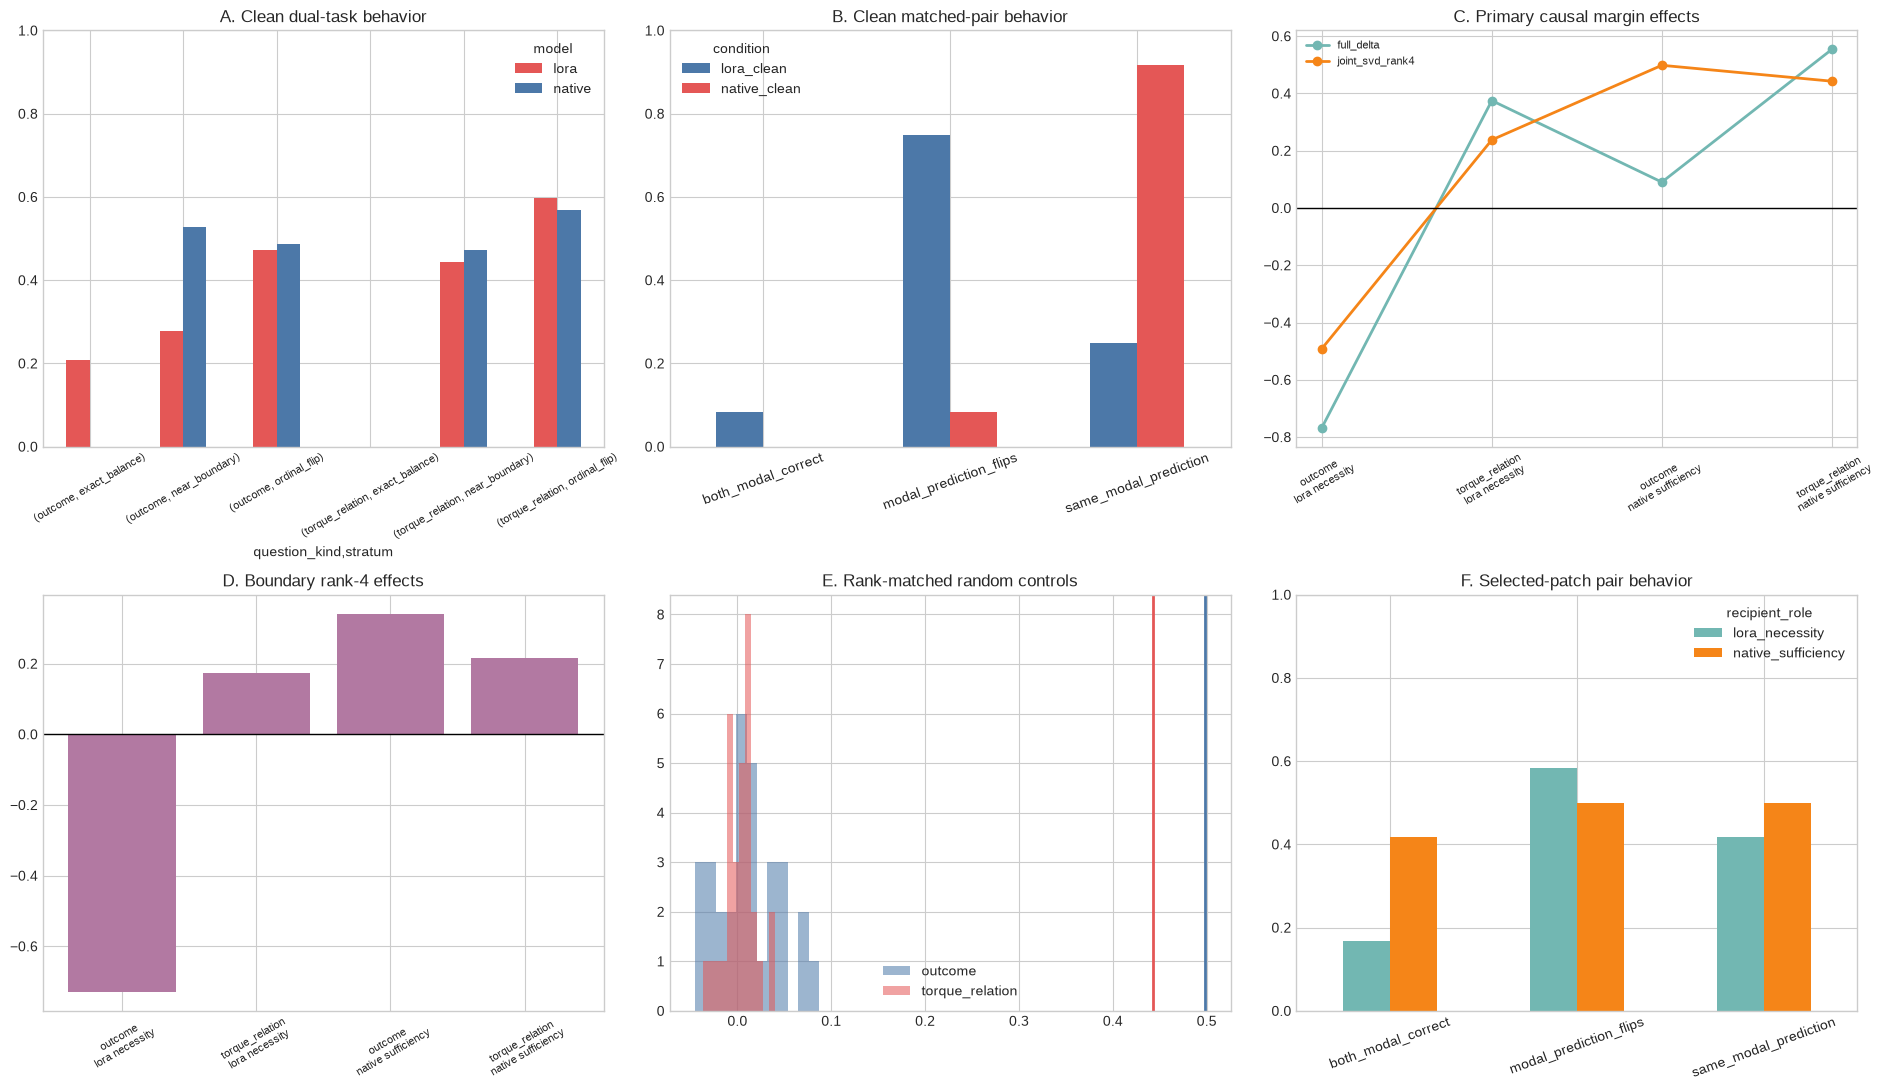

In [14]:
%%cell_progress 13/14 Test task-specific rank-4 mediation and mechanism boundaries
cell_stage('Loading patch shards and computing directional causal effects')
patch_rows = []
for example in test_examples:
    path = PATCH_DIR / f'{safe_example_stem(example.example_id)}.json'
    payload = json.loads(path.read_text(encoding='utf-8'))
    assert payload['example_id'] == example.example_id
    patch_rows.extend(payload['records'])
patch_frame = pd.DataFrame(patch_rows)

clean_lookup = {
    (row['model'], row['example_id']): row
    for row in clean_rows
}
effect_rows = []
for row in patch_rows:
    baseline_model = (
        'native' if row['recipient_role'] == 'native_sufficiency' else 'lora'
    )
    baseline = clean_lookup[(baseline_model, row['example_id'])]
    if row['recipient_role'] == 'native_sufficiency':
        margin_effect = row['correct_margin'] - baseline['correct_margin']
        accuracy_effect = float(row['correct']) - float(baseline['correct'])
        shortcut_reduction = float(baseline['weight_follow']) - float(row['weight_follow'])
    else:
        margin_effect = baseline['correct_margin'] - row['correct_margin']
        accuracy_effect = float(baseline['correct']) - float(row['correct'])
        shortcut_reduction = float(row['weight_follow']) - float(baseline['weight_follow'])
    effect_rows.append({
        **row,
        'baseline_model': baseline_model,
        'margin_effect': float(margin_effect),
        'accuracy_effect': float(accuracy_effect),
        'weight_shortcut_reduction': (
            float(shortcut_reduction) if row['question_kind'] == 'outcome' else np.nan
        ),
    })
effect_frame = pd.DataFrame(effect_rows)
effect_frame.to_csv(ANALYSIS_DIR / 'patch_prompt_effects.csv', index=False)

patch_scene_rows = []
for keys, group in effect_frame.groupby([
    'recipient_role', 'component_name', 'component_family',
    'scene_id', 'question_kind', 'stratum', 'primary',
    'mirror_cluster_id', 'pair_id', 'pair_member',
], dropna=False, sort=True):
    (
        recipient_role, component_name, component_family,
        scene_id, question_kind, stratum, primary,
        mirror_cluster_id, pair_id, pair_member,
    ) = keys
    assert len(group) == 3
    patch_scene_rows.append({
        'recipient_role': recipient_role,
        'component_name': component_name,
        'component_family': component_family,
        'scene_id': scene_id,
        'question_kind': question_kind,
        'stratum': stratum,
        'primary': bool(primary),
        'mirror_cluster_id': mirror_cluster_id,
        'pair_id': pair_id,
        'pair_member': pair_member,
        'gold_semantic': str(group['gold_semantic'].iloc[0]),
        'effect_margin': float(group['margin_effect'].mean()),
        'effect_accuracy': float(group['accuracy_effect'].mean()),
        'weight_shortcut_reduction': float(group['weight_shortcut_reduction'].mean()),
        'patched_accuracy': float(group['correct'].mean()),
        'patched_modal_prediction': modal_semantic(group['predicted_semantic']),
        'component_norm_fraction': float(group['component_norm_fraction'].mean()),
    })
patch_scene = pd.DataFrame(patch_scene_rows)
patch_scene.to_csv(ANALYSIS_DIR / 'patch_scene_effects.csv', index=False)

scope_masks = {
    'all_blind': patch_scene['scene_id'].notna(),
    'ordinal_flip': patch_scene['stratum'] == 'ordinal_flip',
    'near_boundary': patch_scene['stratum'] == 'near_boundary',
    'exact_balance': patch_scene['stratum'] == 'exact_balance',
}
core_summary_rows = []
for scope_index, (scope, mask) in enumerate(scope_masks.items()):
    core = patch_scene[mask & patch_scene['component_name'].isin(CORE_COMPONENTS)]
    for group_index, (keys, group) in enumerate(core.groupby([
        'recipient_role', 'component_name', 'question_kind'
    ], sort=True)):
        recipient_role, component_name, question_kind = keys
        for metric_index, metric in enumerate(
            ('effect_margin', 'effect_accuracy', 'weight_shortcut_reduction')
        ):
            cluster_values = group.groupby('mirror_cluster_id')[metric].mean()
            cluster_values = cluster_values[np.isfinite(cluster_values)]
            if not len(cluster_values):
                continue
            core_summary_rows.append({
                'scope': scope,
                'recipient_role': recipient_role,
                'component_name': component_name,
                'question_kind': question_kind,
                'metric': metric,
                'n_scenes': int(len(group)),
                'n_mirror_clusters': int(len(cluster_values)),
                **bootstrap_values(
                    cluster_values,
                    SEED + 9000 + scope_index * 1000
                    + group_index * 10 + metric_index,
                ),
            })
core_summary = pd.DataFrame(core_summary_rows)
core_summary.to_csv(ANALYSIS_DIR / 'core_causal_summary.csv', index=False)

random_rows = []
random_scene = patch_scene[
    (patch_scene['stratum'] == 'ordinal_flip')
    & (patch_scene['component_family'] == 'random_subspace')
]
for keys, group in random_scene.groupby([
    'recipient_role', 'component_name', 'question_kind'
], sort=True):
    recipient_role, component_name, question_kind = keys
    random_rows.append({
        'recipient_role': recipient_role,
        'component_name': component_name,
        'question_kind': question_kind,
        'effect_margin': float(
            group.groupby('mirror_cluster_id')['effect_margin'].mean().mean()
        ),
    })
random_summary = pd.DataFrame(random_rows)
random_summary.to_csv(ANALYSIS_DIR / 'random_control_summary.csv', index=False)

def core_row(scope, role, component, task, metric='effect_margin'):
    row = core_summary[
        (core_summary['scope'] == scope)
        & (core_summary['recipient_role'] == role)
        & (core_summary['component_name'] == component)
        & (core_summary['question_kind'] == task)
        & (core_summary['metric'] == metric)
    ]
    assert len(row) == 1, (scope, role, component, task, metric)
    return row.iloc[0]

empirical_rows = []
for role in ('native_sufficiency', 'lora_necessity'):
    for task in ('outcome', 'torque_relation'):
        selected_effect = float(core_row(
            'ordinal_flip', role, SELECTED_NAME, task
        )['mean'])
        controls = random_summary[
            (random_summary['recipient_role'] == role)
            & (random_summary['question_kind'] == task)
        ]['effect_margin'].to_numpy()
        assert len(controls) == RANDOM_SUBSPACE_COUNT
        empirical_p = float(
            (1 + np.sum(controls >= selected_effect))
            / (RANDOM_SUBSPACE_COUNT + 1)
        )
        empirical_rows.append({
            'recipient_role': role,
            'question_kind': task,
            'selected_effect': selected_effect,
            'random_mean': float(controls.mean()),
            'random_max': float(controls.max()),
            'empirical_p': empirical_p,
        })
empirical = pd.DataFrame(empirical_rows)
empirical.to_csv(ANALYSIS_DIR / 'random_control_empirical.csv', index=False)

cell_stage('Testing selected rank-4 non-inferiority to the full L50 delta')
noninferiority_rows = []
for role_index, role in enumerate(('native_sufficiency', 'lora_necessity')):
    for task_index, task in enumerate(('outcome', 'torque_relation')):
        group = patch_scene[
            (patch_scene['stratum'] == 'ordinal_flip')
            & (patch_scene['recipient_role'] == role)
            & (patch_scene['question_kind'] == task)
            & patch_scene['component_name'].isin(['full_delta', SELECTED_NAME])
        ].pivot(
            index=['scene_id', 'mirror_cluster_id'],
            columns='component_name', values='effect_margin',
        ).reset_index()
        group['noninferiority_delta'] = (
            group[SELECTED_NAME] - NONINFERIORITY_FRACTION * group['full_delta']
        )
        cluster_values = group.groupby(
            'mirror_cluster_id'
        )['noninferiority_delta'].mean()
        noninferiority_rows.append({
            'recipient_role': role,
            'question_kind': task,
            **bootstrap_values(
                cluster_values, SEED + 11000 + role_index * 10 + task_index
            ),
        })
noninferiority = pd.DataFrame(noninferiority_rows)
noninferiority.to_csv(ANALYSIS_DIR / 'rank4_noninferiority.csv', index=False)

cell_stage('Measuring selected-patch changes on matched outcome pairs')
selected_outcome = patch_scene[
    (patch_scene['stratum'] == 'ordinal_flip')
    & (patch_scene['question_kind'] == 'outcome')
    & (patch_scene['component_name'] == SELECTED_NAME)
]
patch_pair_rows = []
for keys, group in selected_outcome.groupby(['recipient_role', 'pair_id'], sort=True):
    role, pair_id = keys
    assert len(group) == 2
    patch_pair_rows.append({
        'recipient_role': role,
        'pair_id': pair_id,
        'pair_accuracy': float(group['patched_accuracy'].mean()),
        'both_modal_correct': bool(
            (group['patched_modal_prediction'] == group['gold_semantic']).all()
        ),
        'modal_prediction_flips': bool(
            group['patched_modal_prediction'].nunique() == 2
        ),
        'same_modal_prediction': bool(
            group['patched_modal_prediction'].nunique() == 1
        ),
    })
patch_pair_frame = pd.DataFrame(patch_pair_rows)
patch_pair_frame.to_csv(ANALYSIS_DIR / 'selected_patch_pair_behavior.csv', index=False)

pair_comparison_rows = []
for role, baseline_condition in (
    ('native_sufficiency', 'native_clean'),
    ('lora_necessity', 'lora_clean'),
):
    baseline = clean_pair_frame[
        clean_pair_frame['condition'] == baseline_condition
    ].set_index('pair_id')
    patched = patch_pair_frame[
        patch_pair_frame['recipient_role'] == role
    ].set_index('pair_id')
    assert set(baseline.index) == set(patched.index)
    direction = 1.0 if role == 'native_sufficiency' else -1.0
    for metric in (
        'pair_accuracy', 'both_modal_correct',
        'modal_prediction_flips', 'same_modal_prediction',
    ):
        delta = direction * (
            patched[metric].astype(float) - baseline[metric].astype(float)
        )
        pair_comparison_rows.append({
            'recipient_role': role,
            'metric': metric,
            **bootstrap_values(
                delta, SEED + 12000 + len(pair_comparison_rows)
            ),
        })
pair_comparison = pd.DataFrame(pair_comparison_rows)
pair_comparison.to_csv(ANALYSIS_DIR / 'selected_patch_pair_changes.csv', index=False)

def selected_positive(role, task):
    return bool(core_row(
        'ordinal_flip', role, SELECTED_NAME, task
    )['ci_low'] > 0)

def full_positive(role, task):
    return bool(core_row(
        'ordinal_flip', role, 'full_delta', task
    )['ci_low'] > 0)

outcome_causal = all(
    selected_positive(role, 'outcome')
    for role in ('native_sufficiency', 'lora_necessity')
)
relation_causal = all(
    selected_positive(role, 'torque_relation')
    for role in ('native_sufficiency', 'lora_necessity')
)
full_sanity = all(
    full_positive(role, task)
    for role in ('native_sufficiency', 'lora_necessity')
    for task in ('outcome', 'torque_relation')
)
random_specificity = bool((empirical['empirical_p'] <= ALPHA_LEVEL).all())
rank4_noninferior = bool((noninferiority['ci_low'] > 0).all())

if not full_sanity:
    route_classification = 'full_l50_patch_sanity_failed'
elif outcome_causal and relation_causal:
    route_classification = 'shared_torque_relation_to_outcome_mediator'
elif outcome_causal and not relation_causal:
    route_classification = 'outcome_decision_mediator_without_relation_transfer'
elif relation_causal and not outcome_causal:
    route_classification = 'torque_relation_code_without_outcome_mediation'
else:
    route_classification = 'frozen_rank4_route_transfer_not_confirmed'

boundary_status = {}
for task in ('outcome', 'torque_relation'):
    boundary_status[task] = {
        role: core_row('near_boundary', role, SELECTED_NAME, task).to_dict()
        for role in ('native_sufficiency', 'lora_necessity')
    }

gates = {
    'full_delta_positive_both_tasks_both_directions': full_sanity,
    'rank4_outcome_sufficient_and_necessary': outcome_causal,
    'rank4_torque_relation_sufficient_and_necessary': relation_causal,
    'rank4_beats_31_random_controls_all_four_tests': random_specificity,
    'rank4_at_least_80pct_full_all_four_tests': rank4_noninferior,
}
decision = {
    'schema_version': 'qwen27b-l50-metric-route-causal-decision-1.0',
    'route_classification': route_classification,
    'gates': gates,
    'empirical_random_controls': empirical.to_dict(orient='records'),
    'rank4_noninferiority': noninferiority.to_dict(orient='records'),
    'boundary_diagnostic': boundary_status,
    'pair_patch_changes': pair_comparison.to_dict(orient='records'),
    'interpretation_rule': (
        'Route classification uses only new ordinal-flip scenes and frozen '
        'rank4 margin effects. Boundary and balance effects are diagnostics. '
        'Causal mediation at L50 does not imply that the model explicitly '
        'represents a human-readable scalar net torque.'
    ),
}
DECISION_PATH = ANALYSIS_DIR / 'metric_route_causal_decision.json'
write_json_atomic(DECISION_PATH, decision)

display(core_summary[
    (core_summary['metric'] == 'effect_margin')
    & core_summary['component_name'].isin(['full_delta', SELECTED_NAME])
].round(4))
display(empirical.round(4))
display(noninferiority.round(4))
display(pair_comparison.round(4))
print('Route classification:', route_classification)
print('Frozen gates:', gates)

cell_stage('Rendering the dual-task causal summary')
plt.style.use('seaborn-v0_8-whitegrid')
figure, axes = plt.subplots(2, 3, figsize=(19, 11))

clean_plot = clean_scene.groupby(
    ['question_kind', 'stratum', 'model']
)['accuracy'].mean().unstack()
clean_plot.plot(kind='bar', ax=axes[0, 0], color=['#E45756', '#4C78A8'])
axes[0, 0].set_ylim(0, 1)
axes[0, 0].set_title('A. Clean dual-task behavior')
axes[0, 0].tick_params(axis='x', rotation=30, labelsize=8)

clean_pair_frame.groupby('condition')[[
    'both_modal_correct', 'modal_prediction_flips', 'same_modal_prediction'
]].mean().T.plot(kind='bar', ax=axes[0, 1], color=['#4C78A8', '#E45756'])
axes[0, 1].set_ylim(0, 1)
axes[0, 1].set_title('B. Clean matched-pair behavior')
axes[0, 1].tick_params(axis='x', rotation=20)

primary_plot = core_summary[
    (core_summary['scope'] == 'ordinal_flip')
    & (core_summary['metric'] == 'effect_margin')
    & core_summary['component_name'].isin(['full_delta', SELECTED_NAME])
].copy()
primary_plot['label'] = (
    primary_plot['question_kind'] + '\n'
    + primary_plot['recipient_role'].str.replace('_', ' ')
)
for component, color in [('full_delta', '#72B7B2'), (SELECTED_NAME, '#F58518')]:
    subset = primary_plot[primary_plot['component_name'] == component]
    axes[0, 2].plot(
        subset['label'], subset['mean'], marker='o', linewidth=2,
        label=component, color=color,
    )
axes[0, 2].axhline(0, color='black', linewidth=1)
axes[0, 2].set_title('C. Primary causal margin effects')
axes[0, 2].tick_params(axis='x', rotation=30, labelsize=8)
axes[0, 2].legend(fontsize=8)

boundary_plot = core_summary[
    (core_summary['scope'] == 'near_boundary')
    & (core_summary['metric'] == 'effect_margin')
    & (core_summary['component_name'] == SELECTED_NAME)
].copy()
boundary_plot['label'] = (
    boundary_plot['question_kind'] + '\n'
    + boundary_plot['recipient_role'].str.replace('_', ' ')
)
axes[1, 0].bar(boundary_plot['label'], boundary_plot['mean'], color='#B279A2')
axes[1, 0].axhline(0, color='black', linewidth=1)
axes[1, 0].set_title('D. Boundary rank-4 effects')
axes[1, 0].tick_params(axis='x', rotation=30, labelsize=8)

for task, color in [('outcome', '#4C78A8'), ('torque_relation', '#E45756')]:
    subset = random_summary[
        (random_summary['recipient_role'] == 'native_sufficiency')
        & (random_summary['question_kind'] == task)
    ]
    axes[1, 1].hist(
        subset['effect_margin'], bins=12, alpha=0.55,
        label=task, color=color,
    )
    selected_value = float(empirical[
        (empirical['recipient_role'] == 'native_sufficiency')
        & (empirical['question_kind'] == task)
    ]['selected_effect'].iloc[0])
    axes[1, 1].axvline(selected_value, color=color, linewidth=2)
axes[1, 1].set_title('E. Rank-matched random controls')
axes[1, 1].legend()

patch_pair_frame.groupby('recipient_role')[[
    'both_modal_correct', 'modal_prediction_flips', 'same_modal_prediction'
]].mean().T.plot(kind='bar', ax=axes[1, 2], color=['#72B7B2', '#F58518'])
axes[1, 2].set_ylim(0, 1)
axes[1, 2].set_title('F. Selected-patch pair behavior')
axes[1, 2].tick_params(axis='x', rotation=20)

plt.tight_layout()
SUMMARY_FIGURE_PATH = FIGURE_DIR / 'metric_route_causal_summary.png'
plt.savefig(SUMMARY_FIGURE_PATH, dpi=180, bbox_inches='tight')
plt.show()


In [15]:
%%cell_progress 14/14 Verify the complete blind causal package
cell_stage('Checking exact shard and artifact counts')
required_outputs = (
    PROTOCOL_LOCK_PATH, DATASET_LOCK_PATH, MANIFEST_LOCK_PATH,
    CONTROL_LOCK_PATH, RANDOM_SUBSPACE_PATH,
    OUTPUT_ROOT / 'scene_manifest.jsonl',
    OUTPUT_ROOT / 'ordinal_flip_pairs.jsonl', TEST_MANIFEST_PATH,
    CLEAN_DIR / 'identity.json', CLEAN_DIR / 'index.jsonl',
    CLEAN_DIR / 'self_patch_parity.json', PATCH_IDENTITY_PATH,
    ANALYSIS_DIR / 'clean_prompt_predictions.jsonl',
    ANALYSIS_DIR / 'clean_scene_behavior.csv',
    ANALYSIS_DIR / 'clean_paired_changes.csv',
    ANALYSIS_DIR / 'clean_contrast_summary.csv',
    ANALYSIS_DIR / 'clean_pair_behavior.csv',
    ANALYSIS_DIR / 'patch_prompt_effects.csv',
    ANALYSIS_DIR / 'patch_scene_effects.csv',
    ANALYSIS_DIR / 'core_causal_summary.csv',
    ANALYSIS_DIR / 'random_control_summary.csv',
    ANALYSIS_DIR / 'random_control_empirical.csv',
    ANALYSIS_DIR / 'rank4_noninferiority.csv',
    ANALYSIS_DIR / 'selected_patch_pair_behavior.csv',
    ANALYSIS_DIR / 'selected_patch_pair_changes.csv',
    DECISION_PATH, SUMMARY_FIGURE_PATH,
)
missing = [str(path) for path in required_outputs if not Path(path).is_file()]
assert not missing, 'Missing required outputs:\n' + '\n'.join(missing)
assert len(list(CLEAN_DIR.glob('*.pt'))) == len(test_examples)
assert len([
    path for path in PATCH_DIR.glob('*.json')
    if path.name != 'identity.json'
]) == len(test_examples)
assert len(read_jsonl(CLEAN_DIR / 'index.jsonl')) == len(test_examples)

completion = {
    'schema_version': 'qwen27b-l50-metric-route-blind-causal-complete-1.0',
    'completed_at_utc': datetime.now(timezone.utc).isoformat(),
    'model_id': MODEL_ID,
    'model_revision': MODEL_REVISION,
    'adapter_dir': str(ADAPTER_DIR),
    'frozen_layer': L50,
    'frozen_component': SELECTED_NAME,
    'fresh_scenes': len(public_rows),
    'matched_pairs': len(pair_records),
    'dual_task_prompts': len(test_examples),
    'random_subspaces': RANDOM_SUBSPACE_COUNT,
    'decision_path': str(DECISION_PATH),
    'summary_figure_path': str(SUMMARY_FIGURE_PATH),
    'required_outputs': [str(path) for path in required_outputs],
}
RUN_COMPLETE_PATH = OUTPUT_ROOT / 'RUN_COMPLETE.json'
write_json_atomic(RUN_COMPLETE_PATH, completion)
print('Blind metric-route causal validation complete:', RUN_COMPLETE_PATH)
print('Primary decision:', DECISION_PATH)
print('Summary figure:', SUMMARY_FIGURE_PATH)


Verify the complete blind causal package:  93%|#########2| 13/14 [00:00<?, ?cell/s]

Blind metric-route causal validation complete: /content/drive/MyDrive/VisualTorque/results/qwen27b_postlora_l50_metric_route_blind_causal_v1/RUN_COMPLETE.json
Primary decision: /content/drive/MyDrive/VisualTorque/results/qwen27b_postlora_l50_metric_route_blind_causal_v1/analysis/metric_route_causal_decision.json
Summary figure: /content/drive/MyDrive/VisualTorque/results/qwen27b_postlora_l50_metric_route_blind_causal_v1/analysis/figures/metric_route_causal_summary.png
